In [1]:
# ==========================================
# CELL 1 - CONNECT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive connected successfully!")

Mounted at /content/drive
Google Drive connected successfully!


In [2]:
# ==========================================
# CELL 2 - CHECK DATASET ZIP FILES
# ==========================================

import os

DRIVE_PATH = "/content/drive/MyDrive"

print("FILES IN GOOGLE DRIVE")
print("=" * 60)

for item in os.listdir(DRIVE_PATH):
    print(item)

FILES IN GOOGLE DRIVE
Dataset-1.zip
Dataset-2.zip
Colab Notebooks


In [3]:
# ==========================================
# CELL 3 - EXTRACT DATASETS
# ==========================================

import os
import zipfile

# ZIP file locations in Google Drive
ZIP_1 = "/content/drive/MyDrive/Dataset-1.zip"
ZIP_2 = "/content/drive/MyDrive/Dataset-2.zip"

# Local Colab directory
PROJECT_DIR = "/content/brain_tumor_project"

os.makedirs(PROJECT_DIR, exist_ok=True)

# Extract Dataset-1
print("Extracting Dataset-1...")
with zipfile.ZipFile(ZIP_1, "r") as zip_ref:
    zip_ref.extractall(PROJECT_DIR)

print("Dataset-1 extracted successfully!")

# Extract Dataset-2
print("\nExtracting Dataset-2...")
with zipfile.ZipFile(ZIP_2, "r") as zip_ref:
    zip_ref.extractall(PROJECT_DIR)

print("Dataset-2 extracted successfully!")

print("\nBoth datasets extracted!")
print("Location:", PROJECT_DIR)

Extracting Dataset-1...
Dataset-1 extracted successfully!

Extracting Dataset-2...
Dataset-2 extracted successfully!

Both datasets extracted!
Location: /content/brain_tumor_project


In [4]:
# ==========================================
# CELL 4 - VERIFY EXTRACTED STRUCTURE
# ==========================================

import os

print("EXTRACTED DATASET STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    if level <= 4:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

EXTRACTED DATASET STRUCTURE
brain_tumor_project/
    Dataset-1/
        ct/
            tumor/
            healthy/
        mri/
            tumor/
            healthy/
    Dataset-2/
        ct/
            tumor/
            healthy/
        mri/
            tumor/
            healthy/
    __MACOSX/
        Dataset-1/
            ct/
                tumor/
                healthy/
            mri/
                tumor/
                healthy/
        Dataset-2/
            ct/
                tumor/
                healthy/
            mri/
                tumor/
                healthy/


In [5]:
# ==========================================
# CELL 5 - SET DATASET PATHS
# ==========================================

# Dataset paths
DATASET_1 = os.path.join(PROJECT_DIR, "Dataset-1")
DATASET_2 = os.path.join(PROJECT_DIR, "Dataset-2")

# Dataset-1
D1_MRI = os.path.join(DATASET_1, "mri")
D1_CT = os.path.join(DATASET_1, "ct")

# Dataset-2
D2_MRI = os.path.join(DATASET_2, "mri")
D2_CT = os.path.join(DATASET_2, "ct")

print("DATASET PATHS")
print("=" * 60)

paths = {
    "Dataset-1": DATASET_1,
    "Dataset-1 MRI": D1_MRI,
    "Dataset-1 CT": D1_CT,
    "Dataset-2": DATASET_2,
    "Dataset-2 MRI": D2_MRI,
    "Dataset-2 CT": D2_CT
}

for name, path in paths.items():
    print(f"{name:<18}: {path}")
    print(f"{'Exists':<18}: {os.path.exists(path)}")
    print()

DATASET PATHS
Dataset-1         : /content/brain_tumor_project/Dataset-1
Exists            : True

Dataset-1 MRI     : /content/brain_tumor_project/Dataset-1/mri
Exists            : True

Dataset-1 CT      : /content/brain_tumor_project/Dataset-1/ct
Exists            : True

Dataset-2         : /content/brain_tumor_project/Dataset-2
Exists            : True

Dataset-2 MRI     : /content/brain_tumor_project/Dataset-2/mri
Exists            : True

Dataset-2 CT      : /content/brain_tumor_project/Dataset-2/ct
Exists            : True



In [6]:
# ==========================================
# CELL 6 - IMPORT LIBRARIES
# ==========================================

# Basic libraries
import random
import gc
import numpy as np
import pandas as pd

# Image processing
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Image pipeline
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Transfer learning
from tensorflow.keras.applications import EfficientNetB0

# Training callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

All libraries imported successfully!
TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
# ==========================================
# CELL 7 - EXPERIMENT CONFIGURATION
# ==========================================

SEED = 42

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Image configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Classification
CLASS_NAMES = ["healthy", "tumor"]

# Training configuration
EPOCHS = 10

print("EXPERIMENT CONFIGURATION")
print("=" * 50)
print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Classes    :", CLASS_NAMES)
print("Epochs     :", EPOCHS)
print("Seed       :", SEED)

EXPERIMENT CONFIGURATION
Image size : (224, 224)
Batch size : 32
Classes    : ['healthy', 'tumor']
Epochs     : 10
Seed       : 42


In [8]:
# ==========================================
# CELL 8 - COUNT DATASET IMAGES
# ==========================================

def count_images(folder):
    extensions = (
        ".jpg", ".jpeg", ".png",
        ".bmp", ".tif", ".tiff"
    )

    return sum(
        1
        for root, _, files in os.walk(folder)
        for file in files
        if file.lower().endswith(extensions)
    )


dataset_counts = {
    "Dataset-1 MRI Healthy": count_images(
        os.path.join(D1_MRI, "healthy")
    ),
    "Dataset-1 MRI Tumor": count_images(
        os.path.join(D1_MRI, "tumor")
    ),
    "Dataset-1 CT Healthy": count_images(
        os.path.join(D1_CT, "healthy")
    ),
    "Dataset-1 CT Tumor": count_images(
        os.path.join(D1_CT, "tumor")
    ),

    "Dataset-2 MRI Healthy": count_images(
        os.path.join(D2_MRI, "healthy")
    ),
    "Dataset-2 MRI Tumor": count_images(
        os.path.join(D2_MRI, "tumor")
    ),
    "Dataset-2 CT Healthy": count_images(
        os.path.join(D2_CT, "healthy")
    ),
    "Dataset-2 CT Tumor": count_images(
        os.path.join(D2_CT, "tumor")
    )
}

print("DATASET COUNTS")
print("=" * 60)

for name, count in dataset_counts.items():
    print(f"{name:<32}: {count}")

DATASET COUNTS
Dataset-1 MRI Healthy           : 5600
Dataset-1 MRI Tumor             : 5900
Dataset-1 CT Healthy            : 5620
Dataset-1 CT Tumor              : 5662
Dataset-2 MRI Healthy           : 2000
Dataset-2 MRI Tumor             : 3000
Dataset-2 CT Healthy            : 2300
Dataset-2 CT Tumor              : 2318


In [9]:
# ==========================================
# CELL 9 - CREATE DATAFRAMES
# ==========================================

def create_dataframe(modality_path):
    filepaths = []
    labels = []

    for class_name in CLASS_NAMES:
        class_path = os.path.join(modality_path, class_name)

        for filename in os.listdir(class_path):
            filepath = os.path.join(class_path, filename)

            if os.path.isfile(filepath):
                filepaths.append(filepath)
                labels.append(class_name)

    return pd.DataFrame({
        "filepath": filepaths,
        "label": labels
    })


# Create Dataset-1 DataFrames
d1_mri_df = create_dataframe(D1_MRI)
d1_ct_df = create_dataframe(D1_CT)

print("DATASET-1 DATAFRAMES")
print("=" * 50)

print(f"MRI images: {len(d1_mri_df)}")
print(f"CT images : {len(d1_ct_df)}")

print("\nMRI class distribution:")
print(d1_mri_df["label"].value_counts())

print("\nCT class distribution:")
print(d1_ct_df["label"].value_counts())

DATASET-1 DATAFRAMES
MRI images: 11500
CT images : 11282

MRI class distribution:
label
tumor      5900
healthy    5600
Name: count, dtype: int64

CT class distribution:
label
tumor      5662
healthy    5620
Name: count, dtype: int64


In [10]:
# ==========================================
# CELL 10 - BALANCED SAMPLING FUNCTION
# ==========================================

def sample_balanced_modality(df, healthy_count, tumor_count):
    """
    Select an equal number of Healthy and Tumor
    images from one modality.
    """

    healthy_df = df[df["label"] == "healthy"].sample(
        n=healthy_count,
        random_state=SEED
    )

    tumor_df = df[df["label"] == "tumor"].sample(
        n=tumor_count,
        random_state=SEED
    )

    sampled_df = pd.concat(
        [healthy_df, tumor_df],
        ignore_index=True
    )

    # Shuffle selected images
    sampled_df = sampled_df.sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    return sampled_df


print("Balanced sampling function created successfully!")

Balanced sampling function created successfully!


In [11]:
# ==========================================
# CELL 11 - CREATE 50:50 TRAINING DATASET
# ==========================================

MRI_COUNT = 1000
CT_COUNT = 1000

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2


# Sample MRI
mri_50_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_50_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)


# Combine MRI + CT
train_50_df = pd.concat(
    [mri_50_df, ct_50_df],
    ignore_index=True
)

# Shuffle
train_50_df = train_50_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Add modality column
train_50_df["modality"] = train_50_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)


print("50:50 TRAINING DATASET")
print("=" * 50)

print(f"Total images : {len(train_50_df)}")
print(f"MRI images   : {(train_50_df['modality'] == 'MRI').sum()}")
print(f"CT images    : {(train_50_df['modality'] == 'CT').sum()}")

print("\nClass distribution:")
print(pd.crosstab(
    train_50_df["modality"],
    train_50_df["label"]
))

print("\nOverall distribution:")
print(train_50_df["label"].value_counts())

50:50 TRAINING DATASET
Total images : 2000
MRI images   : 1000
CT images    : 1000

Class distribution:
label     healthy  tumor
modality                
CT            500    500
MRI           500    500

Overall distribution:
label
healthy    1000
tumor      1000
Name: count, dtype: int64


In [12]:
# ==========================================
# CELL 12 - TRAIN / VALIDATION SPLIT
# ==========================================

# Create combined stratification label
train_50_df["stratify_key"] = (
    train_50_df["modality"] + "_" + train_50_df["label"]
)

# 80% training, 20% validation
train_50, val_50 = train_test_split(
    train_50_df,
    test_size=0.20,
    stratify=train_50_df["stratify_key"],
    random_state=SEED
)

# Reset indices
train_50 = train_50.reset_index(drop=True)
val_50 = val_50.reset_index(drop=True)

# Remove helper column
train_50 = train_50.drop(columns=["stratify_key"])
val_50 = val_50.drop(columns=["stratify_key"])


print("50:50 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print(f"Training images   : {len(train_50)}")
print(f"Validation images : {len(val_50)}")

print("\nTraining distribution:")
print(pd.crosstab(
    train_50["modality"],
    train_50["label"]
))

print("\nValidation distribution:")
print(pd.crosstab(
    val_50["modality"],
    val_50["label"]
))

50:50 TRAIN / VALIDATION SPLIT
Training images   : 1600
Validation images : 400

Training distribution:
label     healthy  tumor
modality                
CT            400    400
MRI           400    400

Validation distribution:
label     healthy  tumor
modality                
CT            100    100
MRI           100    100


In [13]:
# ==========================================
# CELL 13 - 50:50 DATA GENERATORS
# ==========================================

datagen_50 = ImageDataGenerator()

train_50_generator = datagen_50.flow_from_dataframe(
    dataframe=train_50,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_50_generator = datagen_50.flow_from_dataframe(
    dataframe=val_50,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n50:50 GENERATORS")
print("=" * 50)

print("Training samples  :", train_50_generator.samples)
print("Validation samples:", val_50_generator.samples)

print("\nClass mapping:")
print(train_50_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

50:50 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [14]:
# ==========================================
# CELL 14 - BUILD 50:50 MODEL
# ==========================================

base_model_50 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained feature extractor
base_model_50.trainable = False

model_50 = keras.Sequential([
    base_model_50,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.2),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_50.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model_50.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [15]:
# ==========================================
# CELL 15 - TRAIN 50:50 MODEL
# ==========================================

EPOCHS_50 = 10

early_stopping_50 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_50 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_50 = ModelCheckpoint(
    "/content/model_50_50.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_50 = model_50.fit(
    train_50_generator,
    validation_data=val_50_generator,
    epochs=EPOCHS_50,
    callbacks=[
        early_stopping_50,
        reduce_lr_50,
        checkpoint_50
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.5720 - auc: 0.6291 - loss: 0.6691 - precision: 0.5756 - recall: 0.5265
Epoch 1: val_loss improved from None to 0.51115, saving model to /content/model_50_50.keras

Epoch 1: finished saving model to /content/model_50_50.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 53s 466ms/step - accuracy: 0.6425 - auc: 0.7150 - loss: 0.6208 - precision: 0.6473 - recall: 0.6263 - val_accuracy: 0.7875 - val_auc: 0.8939 - val_loss: 0.5111 - val_precision: 0.7778 - val_recall: 0.8050 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.7651 - auc: 0.8543 - loss: 0.5203 - precision: 0.7784 - recall: 0.7320 
Epoch 2: val_loss improved from 0.51115 to 0.41132, saving model to /content/model_50_50.keras

Epoch 2: finished saving model to /content/model_50_50.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 144ms/step - accuracy: 0.7750 - auc: 0.8631 - loss: 0.5035 - precision: 0.7880 - recall: 0.7525 - val_accuracy: 0.8550 - val_

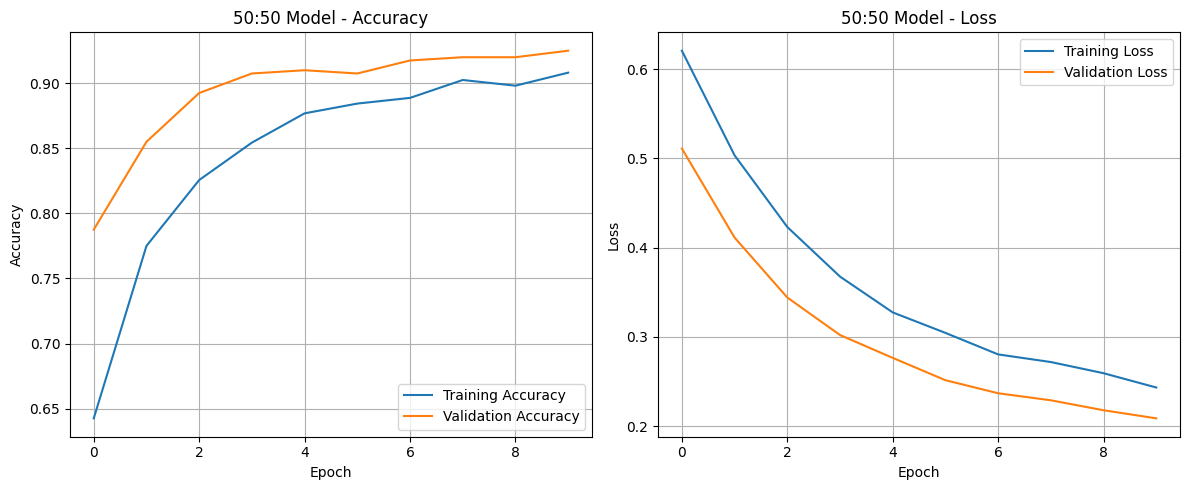

In [16]:
# ==========================================
# CELL 16 - 50:50 TRAINING PERFORMANCE
# ==========================================

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_50.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_50.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("50:50 Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_50.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_50.history["val_loss"],
    label="Validation Loss"
)

plt.title("50:50 Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# CELL 17 - CREATE DATASET-2 DATAFRAMES
# ==========================================

d2_mri_df = create_dataframe(D2_MRI)
d2_ct_df = create_dataframe(D2_CT)

print("DATASET-2")
print("=" * 50)

print(f"MRI images: {len(d2_mri_df)}")
print(f"CT images : {len(d2_ct_df)}")

print("\nMRI class distribution:")
print(d2_mri_df["label"].value_counts())

print("\nCT class distribution:")
print(d2_ct_df["label"].value_counts())

DATASET-2
MRI images: 5000
CT images : 4618

MRI class distribution:
label
tumor      3000
healthy    2000
Name: count, dtype: int64

CT class distribution:
label
tumor      2318
healthy    2300
Name: count, dtype: int64


In [18]:
# ==========================================
# CELL 18 - DATASET-2 TEST GENERATORS
# ==========================================

test_datagen = ImageDataGenerator()

# Dataset-2 MRI
d2_mri_generator = test_datagen.flow_from_dataframe(
    dataframe=d2_mri_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Dataset-2 CT
d2_ct_generator = test_datagen.flow_from_dataframe(
    dataframe=d2_ct_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nDATASET-2 TEST GENERATORS")
print("=" * 50)

print("MRI test samples:", d2_mri_generator.samples)
print("CT test samples :", d2_ct_generator.samples)

print("\nClass mapping:")
print(d2_mri_generator.class_indices)

Found 5000 validated image filenames belonging to 2 classes.
Found 4618 validated image filenames belonging to 2 classes.

DATASET-2 TEST GENERATORS
MRI test samples: 5000
CT test samples : 4618

Class mapping:
{'healthy': 0, 'tumor': 1}


In [19]:
# ==========================================
# CELL 19 - EVALUATE 50:50 MODEL
# ==========================================

print("Evaluating 50:50 model on Dataset-2...")
print("=" * 60)

# Evaluate on MRI
mri_results_50 = model_50.evaluate(
    d2_mri_generator,
    verbose=1
)

# Evaluate on CT
ct_results_50 = model_50.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\nDATASET-2 RESULTS - 50:50 MODEL")
print("=" * 60)

print("\nMRI:")
for name, value in zip(model_50.metrics_names, mri_results_50):
    print(f"{name:<12}: {value:.4f}")

print("\nCT:")
for name, value in zip(model_50.metrics_names, ct_results_50):
    print(f"{name:<12}: {value:.4f}")

Evaluating 50:50 model on Dataset-2...
157/157 ━━━━━━━━━━━━━━━━━━━━ 23s 149ms/step - accuracy: 0.9354 - auc: 0.9828 - loss: 0.1823 - precision: 0.9350 - recall: 0.9590
145/145 ━━━━━━━━━━━━━━━━━━━━ 27s 186ms/step - accuracy: 0.9201 - auc: 0.9710 - loss: 0.2249 - precision: 0.9231 - recall: 0.9172

DATASET-2 RESULTS - 50:50 MODEL

MRI:
loss        : 0.1823
compile_metrics: 0.9354

CT:
loss        : 0.2249
compile_metrics: 0.9201


In [20]:
# ==========================================
# CELL 20 - GENERATE PREDICTIONS (50:50)
# ==========================================

# Reset generators
d2_mri_generator.reset()
d2_ct_generator.reset()

# MRI predictions
mri_prob_50 = model_50.predict(
    d2_mri_generator,
    verbose=1
).ravel()

# CT predictions
ct_prob_50 = model_50.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to binary predictions
mri_pred_50 = (mri_prob_50 >= 0.5).astype(int)
ct_pred_50 = (ct_prob_50 >= 0.5).astype(int)

# True labels
mri_true_50 = d2_mri_generator.classes
ct_true_50 = d2_ct_generator.classes

print("\nPREDICTIONS GENERATED")
print("=" * 50)

print("MRI:")
print("True labels :", len(mri_true_50))
print("Predictions :", len(mri_pred_50))

print("\nCT:")
print("True labels :", len(ct_true_50))
print("Predictions :", len(ct_pred_50))

157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 135ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 162ms/step

PREDICTIONS GENERATED
MRI:
True labels : 5000
Predictions : 5000

CT:
True labels : 4618
Predictions : 4618


In [21]:
# ==========================================
# CELL 21 - DETAILED 50:50 METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_50 = accuracy_score(
    mri_true_50,
    mri_pred_50
)

mri_precision_50 = precision_score(
    mri_true_50,
    mri_pred_50
)

mri_recall_50 = recall_score(
    mri_true_50,
    mri_pred_50
)

mri_f1_50 = f1_score(
    mri_true_50,
    mri_pred_50
)

mri_auc_50 = roc_auc_score(
    mri_true_50,
    mri_prob_50
)

mri_cm_50 = confusion_matrix(
    mri_true_50,
    mri_pred_50
)


# ---------- CT ----------
ct_accuracy_50 = accuracy_score(
    ct_true_50,
    ct_pred_50
)

ct_precision_50 = precision_score(
    ct_true_50,
    ct_pred_50
)

ct_recall_50 = recall_score(
    ct_true_50,
    ct_pred_50
)

ct_f1_50 = f1_score(
    ct_true_50,
    ct_pred_50
)

ct_auc_50 = roc_auc_score(
    ct_true_50,
    ct_prob_50
)

ct_cm_50 = confusion_matrix(
    ct_true_50,
    ct_pred_50
)


# ---------- Print Results ----------
print("DATASET-2 - 50:50 MODEL")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy  : {mri_accuracy_50:.4f}")
print(f"Precision : {mri_precision_50:.4f}")
print(f"Recall    : {mri_recall_50:.4f}")
print(f"F1-Score  : {mri_f1_50:.4f}")
print(f"AUC       : {mri_auc_50:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy  : {ct_accuracy_50:.4f}")
print(f"Precision : {ct_precision_50:.4f}")
print(f"Recall    : {ct_recall_50:.4f}")
print(f"F1-Score  : {ct_f1_50:.4f}")
print(f"AUC       : {ct_auc_50:.4f}")

print("\nMRI CONFUSION MATRIX")
print(mri_cm_50)

print("\nCT CONFUSION MATRIX")
print(ct_cm_50)

DATASET-2 - 50:50 MODEL

MRI RESULTS
------------------------------
Accuracy  : 0.9354
Precision : 0.9350
Recall    : 0.9590
F1-Score  : 0.9468
AUC       : 0.9828

CT RESULTS
------------------------------
Accuracy  : 0.9201
Precision : 0.9231
Recall    : 0.9172
F1-Score  : 0.9201
AUC       : 0.9710

MRI CONFUSION MATRIX
[[1800  200]
 [ 123 2877]]

CT CONFUSION MATRIX
[[2123  177]
 [ 192 2126]]


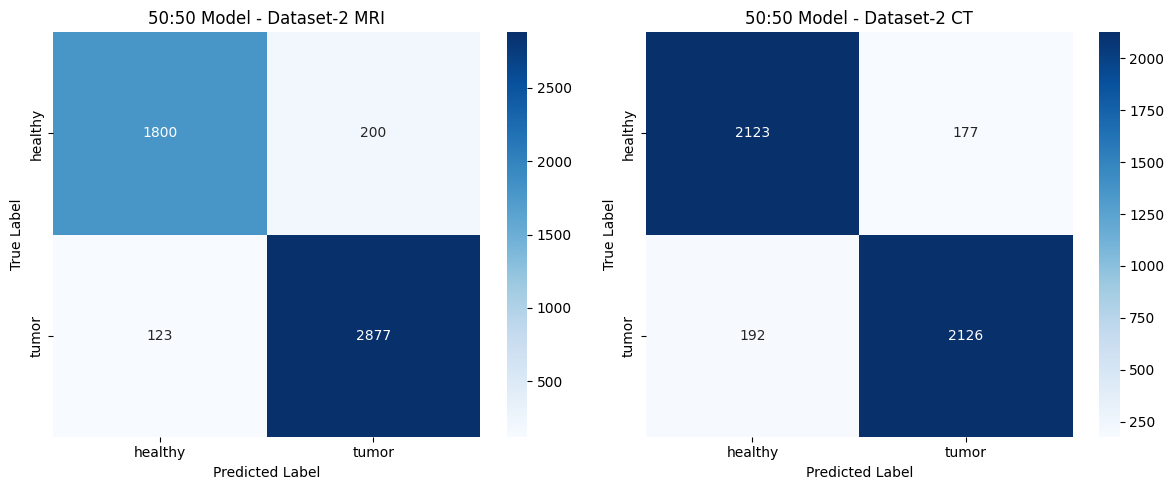

In [22]:
# ==========================================
# CELL 22 - 50:50 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI
sns.heatmap(
    mri_cm_50,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("50:50 Model - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")


# CT
sns.heatmap(
    ct_cm_50,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("50:50 Model - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# CELL 23 - CREATE 40:60 TRAINING DATASET
# ==========================================

MRI_COUNT = 800
CT_COUNT = 1200

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2


# Sample MRI
mri_40_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_60_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)


# Combine
train_40_60_df = pd.concat(
    [mri_40_df, ct_60_df],
    ignore_index=True
)

# Shuffle
train_40_60_df = train_40_60_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Add modality
train_40_60_df["modality"] = train_40_60_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)


print("40:60 TRAINING DATASET")
print("=" * 50)

print(f"Total images : {len(train_40_60_df)}")
print(f"MRI images   : {(train_40_60_df['modality'] == 'MRI').sum()}")
print(f"CT images    : {(train_40_60_df['modality'] == 'CT').sum()}")

print("\nClass distribution:")
print(pd.crosstab(
    train_40_60_df["modality"],
    train_40_60_df["label"]
))

print("\nOverall distribution:")
print(train_40_60_df["label"].value_counts())

40:60 TRAINING DATASET
Total images : 2000
MRI images   : 800
CT images    : 1200

Class distribution:
label     healthy  tumor
modality                
CT            600    600
MRI           400    400

Overall distribution:
label
tumor      1000
healthy    1000
Name: count, dtype: int64


In [24]:
# ==========================================
# CELL 24 - TRAIN / VALIDATION SPLIT
# ==========================================

train_40_60_df["stratify_key"] = (
    train_40_60_df["modality"] + "_" + train_40_60_df["label"]
)

train_40_60, val_40_60 = train_test_split(
    train_40_60_df,
    test_size=0.20,
    stratify=train_40_60_df["stratify_key"],
    random_state=SEED
)

train_40_60 = train_40_60.reset_index(drop=True)
val_40_60 = val_40_60.reset_index(drop=True)

train_40_60 = train_40_60.drop(columns=["stratify_key"])
val_40_60 = val_40_60.drop(columns=["stratify_key"])


print("40:60 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print(f"Training images   : {len(train_40_60)}")
print(f"Validation images : {len(val_40_60)}")

print("\nTraining distribution:")
print(pd.crosstab(
    train_40_60["modality"],
    train_40_60["label"]
))

print("\nValidation distribution:")
print(pd.crosstab(
    val_40_60["modality"],
    val_40_60["label"]
))

40:60 TRAIN / VALIDATION SPLIT
Training images   : 1600
Validation images : 400

Training distribution:
label     healthy  tumor
modality                
CT            480    480
MRI           320    320

Validation distribution:
label     healthy  tumor
modality                
CT            120    120
MRI            80     80


In [25]:
# ==========================================
# CELL 25 - 40:60 DATA GENERATORS
# ==========================================

datagen_40_60 = ImageDataGenerator()

train_40_60_generator = datagen_40_60.flow_from_dataframe(
    dataframe=train_40_60,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_40_60_generator = datagen_40_60.flow_from_dataframe(
    dataframe=val_40_60,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n40:60 GENERATORS")
print("=" * 50)

print("Training samples  :", train_40_60_generator.samples)
print("Validation samples:", val_40_60_generator.samples)

print("\nClass mapping:")
print(train_40_60_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

40:60 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [26]:
# ==========================================
# CELL 26 - BUILD 40:60 MODEL
# ==========================================

base_model_40_60 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_40_60.trainable = False

model_40_60 = keras.Sequential([
    base_model_40_60,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.2),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

model_40_60.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model_40_60.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [27]:
# ==========================================
# CELL 27 - TRAIN 40:60 MODEL
# ==========================================

EPOCHS_40_60 = 10

early_stopping_40_60 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_40_60 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_40_60 = ModelCheckpoint(
    "/content/model_40_60.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_40_60 = model_40_60.fit(
    train_40_60_generator,
    validation_data=val_40_60_generator,
    epochs=EPOCHS_40_60,
    callbacks=[
        early_stopping_40_60,
        reduce_lr_40_60,
        checkpoint_40_60
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5418 - auc: 0.5570 - loss: 0.7114 - precision: 0.5150 - recall: 0.3851
Epoch 1: val_loss improved from None to 0.51814, saving model to /content/model_40_60.keras

Epoch 1: finished saving model to /content/model_40_60.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 39s 391ms/step - accuracy: 0.6075 - auc: 0.6554 - loss: 0.6564 - precision: 0.6194 - recall: 0.5575 - val_accuracy: 0.7925 - val_auc: 0.8779 - val_loss: 0.5181 - val_precision: 0.8000 - val_recall: 0.7800 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.7830 - auc: 0.8583 - loss: 0.5158 - precision: 0.7891 - recall: 0.7670
Epoch 2: val_loss improved from 0.51814 to 0.42162, saving model to /content/model_40_60.keras

Epoch 2: finished saving model to /content/model_40_60.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 149ms/step - accuracy: 0.7894 - auc: 0.8624 - loss: 0.5050 - precision: 0.8083 - recall: 0.7588 - val_accuracy: 0.8500 - val_

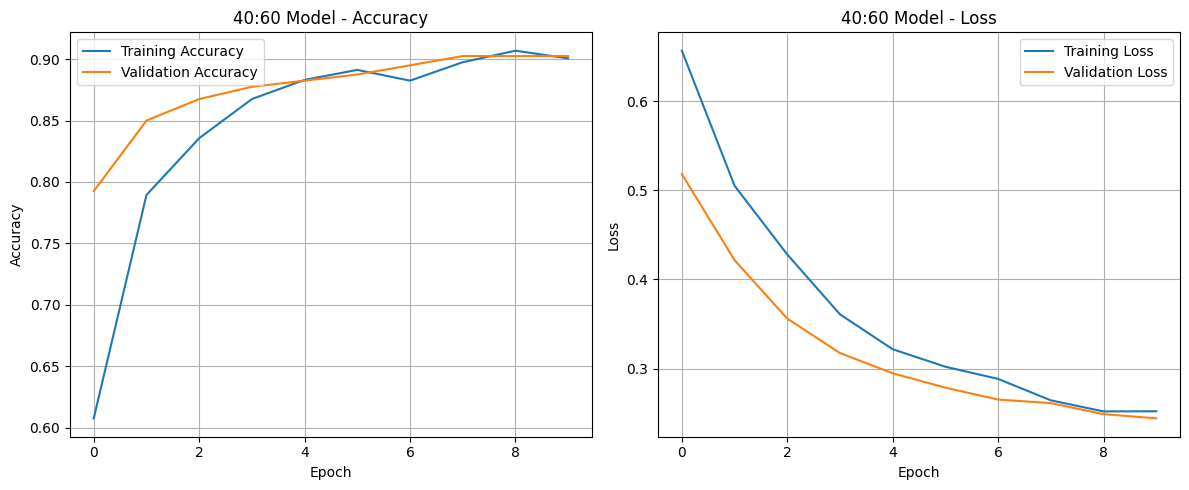

In [28]:
# ==========================================
# CELL 28 - 40:60 TRAINING PERFORMANCE
# ==========================================

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_40_60.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_40_60.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("40:60 Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_40_60.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_40_60.history["val_loss"],
    label="Validation Loss"
)

plt.title("40:60 Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# CELL 29 - EVALUATE 40:60 MODEL
# ==========================================

print("Evaluating 40:60 model on Dataset-2...")
print("=" * 60)

# MRI evaluation
mri_results_40_60 = model_40_60.evaluate(
    d2_mri_generator,
    verbose=1
)

# CT evaluation
ct_results_40_60 = model_40_60.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\nDATASET-2 RESULTS - 40:60 MODEL")
print("=" * 60)

print("\nMRI:")
for name, value in zip(
    model_40_60.metrics_names,
    mri_results_40_60
):
    print(f"{name:<12}: {value:.4f}")

print("\nCT:")
for name, value in zip(
    model_40_60.metrics_names,
    ct_results_40_60
):
    print(f"{name:<12}: {value:.4f}")

Evaluating 40:60 model on Dataset-2...
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 125ms/step - accuracy: 0.9228 - auc: 0.9778 - loss: 0.2047 - precision: 0.9203 - recall: 0.9540
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 168ms/step - accuracy: 0.9275 - auc: 0.9747 - loss: 0.2059 - precision: 0.9448 - recall: 0.9085

DATASET-2 RESULTS - 40:60 MODEL

MRI:
loss        : 0.2047
compile_metrics: 0.9228

CT:
loss        : 0.2059
compile_metrics: 0.9275


In [30]:
# ==========================================
# CELL 30 - GENERATE 40:60 PREDICTIONS
# ==========================================

# Reset generators
d2_mri_generator.reset()
d2_ct_generator.reset()

# MRI predictions
mri_prob_40_60 = model_40_60.predict(
    d2_mri_generator,
    verbose=1
).ravel()

# CT predictions
ct_prob_40_60 = model_40_60.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to binary predictions
mri_pred_40_60 = (
    mri_prob_40_60 >= 0.5
).astype(int)

ct_pred_40_60 = (
    ct_prob_40_60 >= 0.5
).astype(int)

# True labels
mri_true_40_60 = d2_mri_generator.classes
ct_true_40_60 = d2_ct_generator.classes

print("\n40:60 PREDICTIONS GENERATED")
print("=" * 50)

print("MRI:")
print("True labels :", len(mri_true_40_60))
print("Predictions :", len(mri_pred_40_60))

print("\nCT:")
print("True labels :", len(ct_true_40_60))
print("Predictions :", len(ct_pred_40_60))

157/157 ━━━━━━━━━━━━━━━━━━━━ 26s 128ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 159ms/step

40:60 PREDICTIONS GENERATED
MRI:
True labels : 5000
Predictions : 5000

CT:
True labels : 4618
Predictions : 4618


In [31]:
# ==========================================
# CELL 31 - DETAILED 40:60 METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_40_60 = accuracy_score(
    mri_true_40_60,
    mri_pred_40_60
)

mri_precision_40_60 = precision_score(
    mri_true_40_60,
    mri_pred_40_60
)

mri_recall_40_60 = recall_score(
    mri_true_40_60,
    mri_pred_40_60
)

mri_f1_40_60 = f1_score(
    mri_true_40_60,
    mri_pred_40_60
)

mri_auc_40_60 = roc_auc_score(
    mri_true_40_60,
    mri_prob_40_60
)

mri_cm_40_60 = confusion_matrix(
    mri_true_40_60,
    mri_pred_40_60
)


# ---------- CT ----------
ct_accuracy_40_60 = accuracy_score(
    ct_true_40_60,
    ct_pred_40_60
)

ct_precision_40_60 = precision_score(
    ct_true_40_60,
    ct_pred_40_60
)

ct_recall_40_60 = recall_score(
    ct_true_40_60,
    ct_pred_40_60
)

ct_f1_40_60 = f1_score(
    ct_true_40_60,
    ct_pred_40_60
)

ct_auc_40_60 = roc_auc_score(
    ct_true_40_60,
    ct_prob_40_60
)

ct_cm_40_60 = confusion_matrix(
    ct_true_40_60,
    ct_pred_40_60
)


# ---------- Print Results ----------
print("DATASET-2 - 40:60 MODEL")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy  : {mri_accuracy_40_60:.4f}")
print(f"Precision : {mri_precision_40_60:.4f}")
print(f"Recall    : {mri_recall_40_60:.4f}")
print(f"F1-Score  : {mri_f1_40_60:.4f}")
print(f"AUC       : {mri_auc_40_60:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy  : {ct_accuracy_40_60:.4f}")
print(f"Precision : {ct_precision_40_60:.4f}")
print(f"Recall    : {ct_recall_40_60:.4f}")
print(f"F1-Score  : {ct_f1_40_60:.4f}")
print(f"AUC       : {ct_auc_40_60:.4f}")

print("\nMRI CONFUSION MATRIX")
print(mri_cm_40_60)

print("\nCT CONFUSION MATRIX")
print(ct_cm_40_60)

DATASET-2 - 40:60 MODEL

MRI RESULTS
------------------------------
Accuracy  : 0.9228
Precision : 0.9203
Recall    : 0.9540
F1-Score  : 0.9368
AUC       : 0.9779

CT RESULTS
------------------------------
Accuracy  : 0.9275
Precision : 0.9448
Recall    : 0.9085
F1-Score  : 0.9263
AUC       : 0.9747

MRI CONFUSION MATRIX
[[1752  248]
 [ 138 2862]]

CT CONFUSION MATRIX
[[2177  123]
 [ 212 2106]]


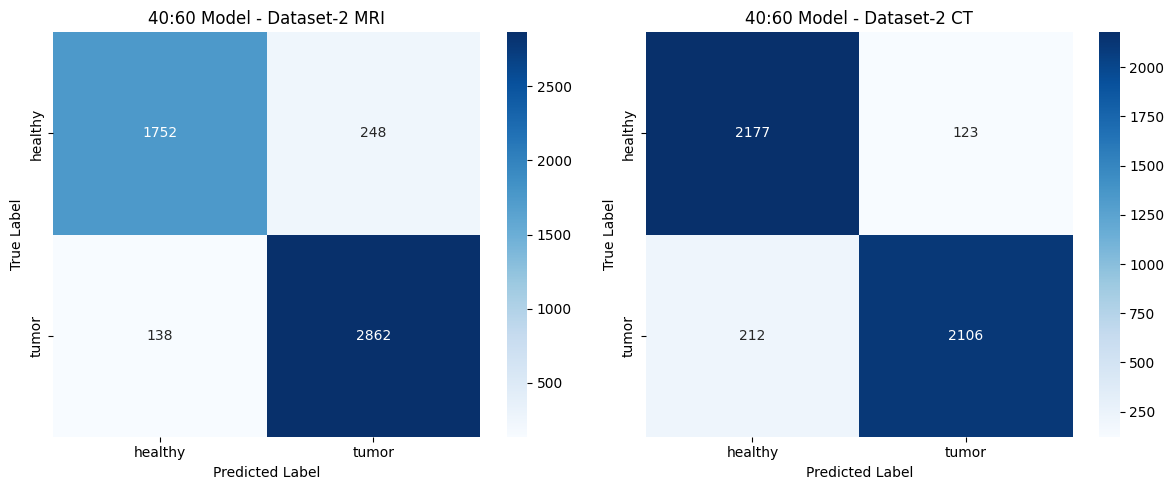

In [32]:
# ==========================================
# CELL 32 - 40:60 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI confusion matrix
sns.heatmap(
    mri_cm_40_60,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("40:60 Model - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")


# CT confusion matrix
sns.heatmap(
    ct_cm_40_60,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("40:60 Model - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [33]:
# ==========================================
# CELL 33 - CREATE 60:40 TRAINING DATASET
# ==========================================

MRI_COUNT = 1200
CT_COUNT = 800

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2


# Sample MRI
mri_60_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_40_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)


# Combine
train_60_40_df = pd.concat(
    [mri_60_df, ct_40_df],
    ignore_index=True
)

# Shuffle
train_60_40_df = train_60_40_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Add modality
train_60_40_df["modality"] = train_60_40_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)


print("60:40 TRAINING DATASET")
print("=" * 50)

print(f"Total images : {len(train_60_40_df)}")
print(f"MRI images   : {(train_60_40_df['modality'] == 'MRI').sum()}")
print(f"CT images    : {(train_60_40_df['modality'] == 'CT').sum()}")

print("\nClass distribution:")
print(pd.crosstab(
    train_60_40_df["modality"],
    train_60_40_df["label"]
))

print("\nOverall distribution:")
print(train_60_40_df["label"].value_counts())

60:40 TRAINING DATASET
Total images : 2000
MRI images   : 1200
CT images    : 800

Class distribution:
label     healthy  tumor
modality                
CT            400    400
MRI           600    600

Overall distribution:
label
healthy    1000
tumor      1000
Name: count, dtype: int64


In [34]:
# ==========================================
# CELL 34 - TRAIN / VALIDATION SPLIT
# ==========================================

train_60_40_df["stratify_key"] = (
    train_60_40_df["modality"] + "_" + train_60_40_df["label"]
)

train_60_40, val_60_40 = train_test_split(
    train_60_40_df,
    test_size=0.20,
    stratify=train_60_40_df["stratify_key"],
    random_state=SEED
)

train_60_40 = train_60_40.reset_index(drop=True)
val_60_40 = val_60_40.reset_index(drop=True)

train_60_40 = train_60_40.drop(columns=["stratify_key"])
val_60_40 = val_60_40.drop(columns=["stratify_key"])


print("60:40 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print(f"Training images   : {len(train_60_40)}")
print(f"Validation images : {len(val_60_40)}")

print("\nTraining distribution:")
print(pd.crosstab(
    train_60_40["modality"],
    train_60_40["label"]
))

print("\nValidation distribution:")
print(pd.crosstab(
    val_60_40["modality"],
    val_60_40["label"]
))

60:40 TRAIN / VALIDATION SPLIT
Training images   : 1600
Validation images : 400

Training distribution:
label     healthy  tumor
modality                
CT            320    320
MRI           480    480

Validation distribution:
label     healthy  tumor
modality                
CT             80     80
MRI           120    120


In [35]:
# ==========================================
# CELL 35 - 60:40 DATA GENERATORS
# ==========================================

datagen_60_40 = ImageDataGenerator()

train_60_40_generator = datagen_60_40.flow_from_dataframe(
    dataframe=train_60_40,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_60_40_generator = datagen_60_40.flow_from_dataframe(
    dataframe=val_60_40,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n60:40 GENERATORS")
print("=" * 50)
print("Training samples  :", train_60_40_generator.samples)
print("Validation samples:", val_60_40_generator.samples)

print("\nClass mapping:")
print(train_60_40_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

60:40 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [36]:
# ==========================================
# CELL 36 - 60:40 MODEL
# ==========================================

base_model_60_40 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_60_40.trainable = False

model_60_40 = keras.Sequential([
    base_model_60_40,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_60_40.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("60:40 EfficientNetB0 model created successfully!")
model_60_40.summary()

60:40 EfficientNetB0 model created successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [37]:
# ==========================================
# CELL 37 - TRAIN 60:40 MODEL
# ==========================================

EPOCHS_60_40 = 10

early_stopping_60_40 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_60_40 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_60_40 = ModelCheckpoint(
    "/content/model_60_40.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_60_40 = model_60_40.fit(
    train_60_40_generator,
    validation_data=val_60_40_generator,
    epochs=EPOCHS_60_40,
    callbacks=[
        early_stopping_60_40,
        reduce_lr_60_40,
        checkpoint_60_40
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5840 - auc: 0.6184 - loss: 0.6790 - precision: 0.5775 - recall: 0.6560
Epoch 1: val_loss improved from None to 0.49047, saving model to /content/model_60_40.keras

Epoch 1: finished saving model to /content/model_60_40.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 374ms/step - accuracy: 0.6325 - auc: 0.6813 - loss: 0.6437 - precision: 0.6345 - recall: 0.6250 - val_accuracy: 0.8425 - val_auc: 0.9219 - val_loss: 0.4905 - val_precision: 0.8513 - val_recall: 0.8300 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.7811 - auc: 0.8511 - loss: 0.5183 - precision: 0.7785 - recall: 0.7775
Epoch 2: val_loss improved from 0.49047 to 0.37930, saving model to /content/model_60_40.keras

Epoch 2: finished saving model to /content/model_60_40.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.7831 - auc: 0.8609 - loss: 0.5059 - precision: 0.7885 - recall: 0.7738 - val_accuracy: 0.8850 - val_a

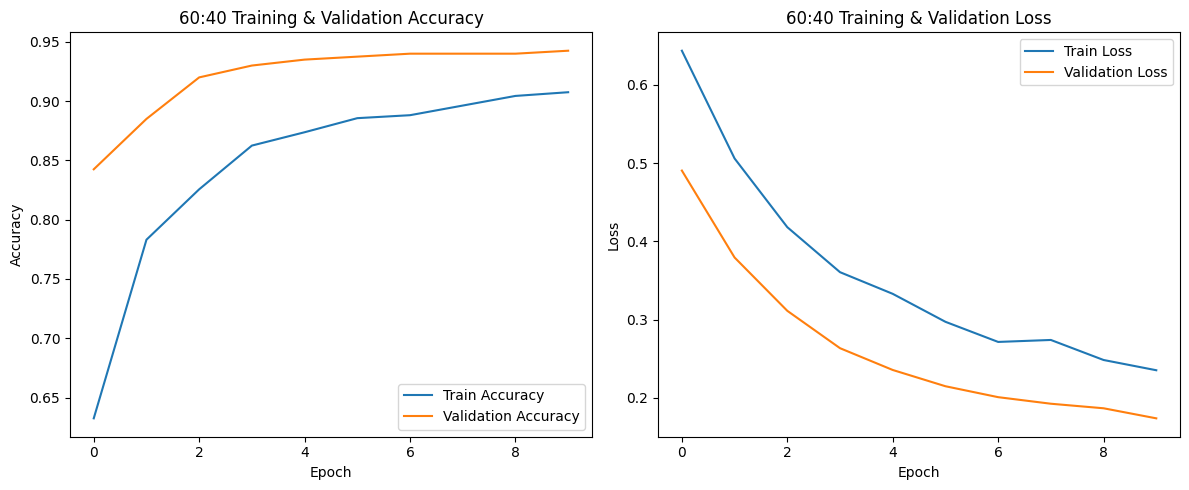

In [38]:
# ==========================================
# CELL 38 - 60:40 TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_60_40.history["accuracy"], label="Train Accuracy")
plt.plot(history_60_40.history["val_accuracy"], label="Validation Accuracy")
plt.title("60:40 Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_60_40.history["loss"], label="Train Loss")
plt.plot(history_60_40.history["val_loss"], label="Validation Loss")
plt.title("60:40 Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [39]:
# ==========================================
# CELL 39 - 60:40 DATASET-2 EVALUATION
# ==========================================

print("Evaluating 60:40 model on Dataset-2 MRI...")
mri_results_60_40 = model_60_40.evaluate(
    d2_mri_generator,
    verbose=1
)

print("\nEvaluating 60:40 model on Dataset-2 CT...")
ct_results_60_40 = model_60_40.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\n60:40 EVALUATION COMPLETED")

Evaluating 60:40 model on Dataset-2 MRI...
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 128ms/step - accuracy: 0.9398 - auc: 0.9849 - loss: 0.1703 - precision: 0.9479 - recall: 0.9520

Evaluating 60:40 model on Dataset-2 CT...
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 161ms/step - accuracy: 0.9073 - auc: 0.9656 - loss: 0.2443 - precision: 0.9145 - recall: 0.8995

60:40 EVALUATION COMPLETED


In [40]:
# ==========================================
# CELL 40 - 60:40 PREDICTIONS
# ==========================================

# Reset generators before prediction
d2_mri_generator.reset()
d2_ct_generator.reset()

# Predict probabilities
mri_prob_60_40 = model_60_40.predict(
    d2_mri_generator,
    verbose=1
).ravel()

ct_prob_60_40 = model_60_40.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to class predictions
mri_pred_60_40 = (mri_prob_60_40 >= 0.5).astype(int)
ct_pred_60_40 = (ct_prob_60_40 >= 0.5).astype(int)

# True labels
mri_true_60_40 = d2_mri_generator.classes
ct_true_60_40 = d2_ct_generator.classes

print("\n60:40 predictions generated successfully!")
print("MRI predictions:", len(mri_pred_60_40))
print("CT predictions :", len(ct_pred_60_40))

157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 136ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 162ms/step

60:40 predictions generated successfully!
MRI predictions: 5000
CT predictions : 4618


In [41]:
# ==========================================
# CELL 41 - 60:40 DETAILED METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_60_40 = accuracy_score(
    mri_true_60_40,
    mri_pred_60_40
)

mri_precision_60_40 = precision_score(
    mri_true_60_40,
    mri_pred_60_40
)

mri_recall_60_40 = recall_score(
    mri_true_60_40,
    mri_pred_60_40
)

mri_f1_60_40 = f1_score(
    mri_true_60_40,
    mri_pred_60_40
)

mri_auc_60_40 = roc_auc_score(
    mri_true_60_40,
    mri_prob_60_40
)

mri_cm_60_40 = confusion_matrix(
    mri_true_60_40,
    mri_pred_60_40
)


# ---------- CT ----------
ct_accuracy_60_40 = accuracy_score(
    ct_true_60_40,
    ct_pred_60_40
)

ct_precision_60_40 = precision_score(
    ct_true_60_40,
    ct_pred_60_40
)

ct_recall_60_40 = recall_score(
    ct_true_60_40,
    ct_pred_60_40
)

ct_f1_60_40 = f1_score(
    ct_true_60_40,
    ct_pred_60_40
)

ct_auc_60_40 = roc_auc_score(
    ct_true_60_40,
    ct_prob_60_40
)

ct_cm_60_40 = confusion_matrix(
    ct_true_60_40,
    ct_pred_60_40
)


# ---------- Print Results ----------
print("60:40 RESULTS ON DATASET-2")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy : {mri_accuracy_60_40:.4f}")
print(f"Precision: {mri_precision_60_40:.4f}")
print(f"Recall   : {mri_recall_60_40:.4f}")
print(f"F1 Score : {mri_f1_60_40:.4f}")
print(f"AUC      : {mri_auc_60_40:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy : {ct_accuracy_60_40:.4f}")
print(f"Precision: {ct_precision_60_40:.4f}")
print(f"Recall   : {ct_recall_60_40:.4f}")
print(f"F1 Score : {ct_f1_60_40:.4f}")
print(f"AUC      : {ct_auc_60_40:.4f}")

60:40 RESULTS ON DATASET-2

MRI RESULTS
------------------------------
Accuracy : 0.9398
Precision: 0.9479
Recall   : 0.9520
F1 Score : 0.9499
AUC      : 0.9849

CT RESULTS
------------------------------
Accuracy : 0.9073
Precision: 0.9145
Recall   : 0.8995
F1 Score : 0.9069
AUC      : 0.9656


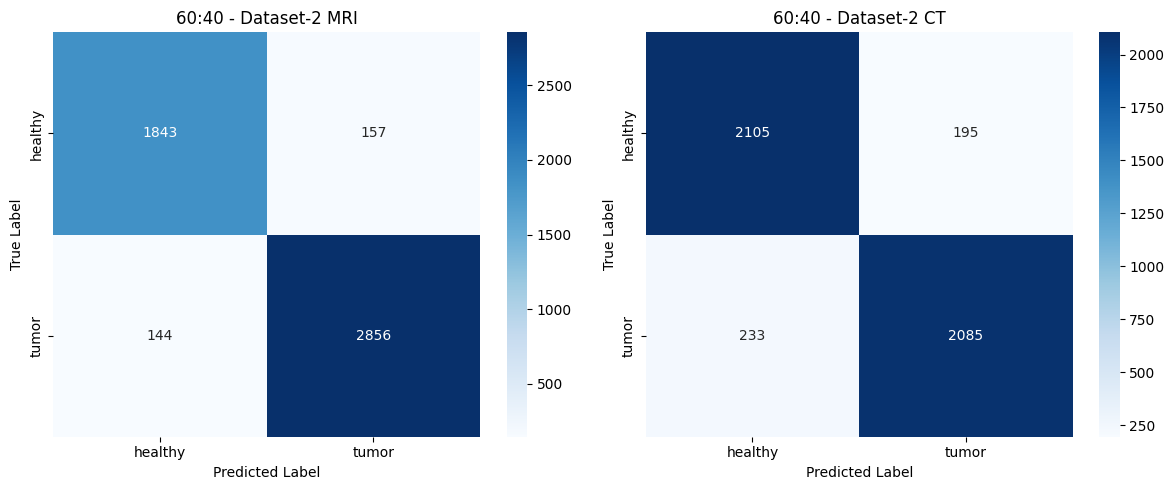

In [42]:
# ==========================================
# CELL 42 - 60:40 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI Confusion Matrix
sns.heatmap(
    mri_cm_60_40,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("60:40 - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# CT Confusion Matrix
sns.heatmap(
    ct_cm_60_40,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("60:40 - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [43]:
# ==========================================
# CELL 43 - CREATE 30:70 DATASET
# ==========================================

# MRI = 30% = 600 images
# CT  = 70% = 1400 images
# Each modality remains class-balanced

MRI_COUNT = 600
CT_COUNT = 1400

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2

# Sample MRI
mri_30_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_70_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)

# Combine MRI + CT
train_30_70_df = pd.concat(
    [mri_30_df, ct_70_df],
    ignore_index=True
)

# Shuffle
train_30_70_df = train_30_70_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Add modality column
train_30_70_df["modality"] = train_30_70_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)

print("30:70 DATASET")
print("=" * 50)
print("Total images:", len(train_30_70_df))

print("\nModality distribution:")
print(train_30_70_df["modality"].value_counts())

print("\nModality + class distribution:")
print(
    train_30_70_df.groupby(
        ["modality", "label"]
    ).size()
)

30:70 DATASET
Total images: 2000

Modality distribution:
modality
CT     1400
MRI     600
Name: count, dtype: int64

Modality + class distribution:
modality  label  
CT        healthy    700
          tumor      700
MRI       healthy    300
          tumor      300
dtype: int64


In [44]:
# ==========================================
# CELL 44 - 30:70 TRAIN/VALIDATION SPLIT
# ==========================================

# Create a combined stratification column
train_30_70_df["stratify_group"] = (
    train_30_70_df["modality"] + "_" +
    train_30_70_df["label"]
)

train_30_70, val_30_70 = train_test_split(
    train_30_70_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_30_70_df["stratify_group"]
)

# Reset indices
train_30_70 = train_30_70.reset_index(drop=True)
val_30_70 = val_30_70.reset_index(drop=True)

print("30:70 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print("Training samples  :", len(train_30_70))
print("Validation samples:", len(val_30_70))

print("\nTraining distribution:")
print(
    train_30_70.groupby(
        ["modality", "label"]
    ).size()
)

print("\nValidation distribution:")
print(
    val_30_70.groupby(
        ["modality", "label"]
    ).size()
)

30:70 TRAIN / VALIDATION SPLIT
Training samples  : 1600
Validation samples: 400

Training distribution:
modality  label  
CT        healthy    560
          tumor      560
MRI       healthy    240
          tumor      240
dtype: int64

Validation distribution:
modality  label  
CT        healthy    140
          tumor      140
MRI       healthy     60
          tumor       60
dtype: int64


In [45]:
# ==========================================
# CELL 45 - 30:70 DATA GENERATORS
# ==========================================

datagen_30_70 = ImageDataGenerator()

train_30_70_generator = datagen_30_70.flow_from_dataframe(
    dataframe=train_30_70,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_30_70_generator = datagen_30_70.flow_from_dataframe(
    dataframe=val_30_70,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n30:70 GENERATORS")
print("=" * 50)
print("Training samples  :", train_30_70_generator.samples)
print("Validation samples:", val_30_70_generator.samples)

print("\nClass mapping:")
print(train_30_70_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

30:70 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [46]:
# ==========================================
# CELL 46 - 30:70 MODEL
# ==========================================

base_model_30_70 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_30_70.trainable = False

model_30_70 = keras.Sequential([
    base_model_30_70,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_30_70.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("30:70 EfficientNetB0 model created successfully!")
model_30_70.summary()

30:70 EfficientNetB0 model created successfully!


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [47]:
# ==========================================
# CELL 47 - TRAIN 30:70 MODEL
# ==========================================

EPOCHS_30_70 = 10

early_stopping_30_70 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_30_70 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_30_70 = ModelCheckpoint(
    "/content/model_30_70.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_30_70 = model_30_70.fit(
    train_30_70_generator,
    validation_data=val_30_70_generator,
    epochs=EPOCHS_30_70,
    callbacks=[
        early_stopping_30_70,
        reduce_lr_30_70,
        checkpoint_30_70
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5837 - auc: 0.6158 - loss: 0.6743 - precision: 0.5912 - recall: 0.4681
Epoch 1: val_loss improved from None to 0.49785, saving model to /content/model_30_70.keras

Epoch 1: finished saving model to /content/model_30_70.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 378ms/step - accuracy: 0.6513 - auc: 0.7140 - loss: 0.6214 - precision: 0.6640 - recall: 0.6125 - val_accuracy: 0.8375 - val_auc: 0.8975 - val_loss: 0.4978 - val_precision: 0.8534 - val_recall: 0.8150 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.7910 - auc: 0.8701 - loss: 0.4954 - precision: 0.8171 - recall: 0.7612
Epoch 2: val_loss improved from 0.49785 to 0.39416, saving model to /content/model_30_70.keras

Epoch 2: finished saving model to /content/model_30_70.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 153ms/step - accuracy: 0.8081 - auc: 0.8888 - loss: 0.4706 - precision: 0.8265 - recall: 0.7800 - val_accuracy: 0.8550 - val_

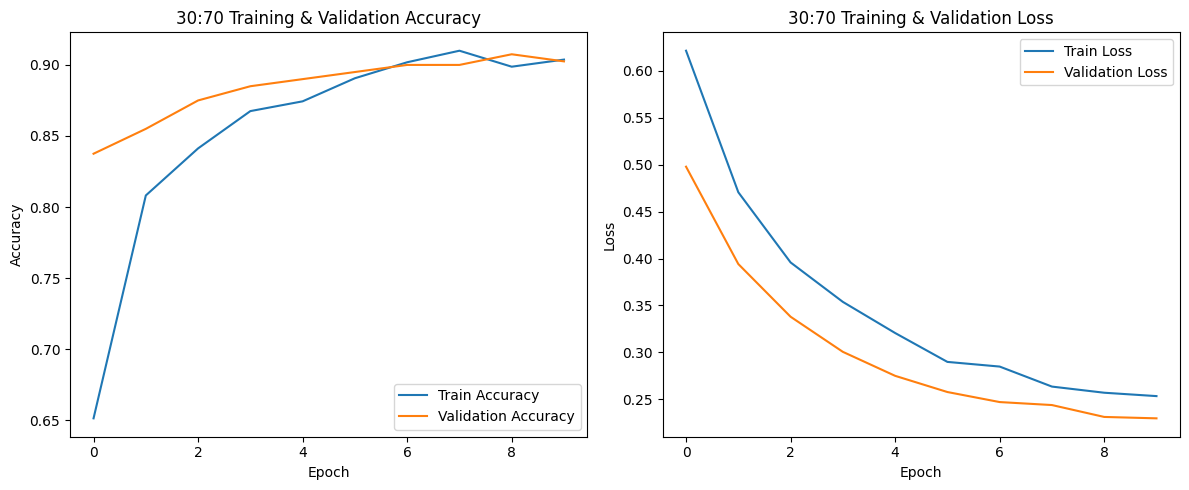

In [48]:
# ==========================================
# CELL 48 - 30:70 TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_30_70.history["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    history_30_70.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("30:70 Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_30_70.history["loss"],
    label="Train Loss"
)
plt.plot(
    history_30_70.history["val_loss"],
    label="Validation Loss"
)
plt.title("30:70 Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [49]:
# ==========================================
# CELL 49 - 30:70 DATASET-2 EVALUATION
# ==========================================

print("Evaluating 30:70 model on Dataset-2 MRI...")
mri_results_30_70 = model_30_70.evaluate(
    d2_mri_generator,
    verbose=1
)

print("\nEvaluating 30:70 model on Dataset-2 CT...")
ct_results_30_70 = model_30_70.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\n30:70 EVALUATION COMPLETED")

Evaluating 30:70 model on Dataset-2 MRI...
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.9202 - auc: 0.9776 - loss: 0.2125 - precision: 0.9109 - recall: 0.9610

Evaluating 30:70 model on Dataset-2 CT...
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 164ms/step - accuracy: 0.9225 - auc: 0.9756 - loss: 0.2075 - precision: 0.9228 - recall: 0.9228

30:70 EVALUATION COMPLETED


In [50]:
# ==========================================
# CELL 50 - 30:70 PREDICTIONS
# ==========================================

# Reset generators before prediction
d2_mri_generator.reset()
d2_ct_generator.reset()

# Predict probabilities
mri_prob_30_70 = model_30_70.predict(
    d2_mri_generator,
    verbose=1
).ravel()

ct_prob_30_70 = model_30_70.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to class predictions
mri_pred_30_70 = (mri_prob_30_70 >= 0.5).astype(int)
ct_pred_30_70 = (ct_prob_30_70 >= 0.5).astype(int)

# True labels
mri_true_30_70 = d2_mri_generator.classes
ct_true_30_70 = d2_ct_generator.classes

print("\n30:70 predictions generated successfully!")
print("MRI predictions:", len(mri_pred_30_70))
print("CT predictions :", len(ct_pred_30_70))

157/157 ━━━━━━━━━━━━━━━━━━━━ 26s 132ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step

30:70 predictions generated successfully!
MRI predictions: 5000
CT predictions : 4618


In [51]:
# ==========================================
# CELL 51 - 30:70 DETAILED METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_30_70 = accuracy_score(
    mri_true_30_70,
    mri_pred_30_70
)

mri_precision_30_70 = precision_score(
    mri_true_30_70,
    mri_pred_30_70
)

mri_recall_30_70 = recall_score(
    mri_true_30_70,
    mri_pred_30_70
)

mri_f1_30_70 = f1_score(
    mri_true_30_70,
    mri_pred_30_70
)

mri_auc_30_70 = roc_auc_score(
    mri_true_30_70,
    mri_prob_30_70
)

mri_cm_30_70 = confusion_matrix(
    mri_true_30_70,
    mri_pred_30_70
)


# ---------- CT ----------
ct_accuracy_30_70 = accuracy_score(
    ct_true_30_70,
    ct_pred_30_70
)

ct_precision_30_70 = precision_score(
    ct_true_30_70,
    ct_pred_30_70
)

ct_recall_30_70 = recall_score(
    ct_true_30_70,
    ct_pred_30_70
)

ct_f1_30_70 = f1_score(
    ct_true_30_70,
    ct_pred_30_70
)

ct_auc_30_70 = roc_auc_score(
    ct_true_30_70,
    ct_prob_30_70
)

ct_cm_30_70 = confusion_matrix(
    ct_true_30_70,
    ct_pred_30_70
)


# ---------- Print Results ----------
print("30:70 RESULTS ON DATASET-2")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy : {mri_accuracy_30_70:.4f}")
print(f"Precision: {mri_precision_30_70:.4f}")
print(f"Recall   : {mri_recall_30_70:.4f}")
print(f"F1 Score : {mri_f1_30_70:.4f}")
print(f"AUC      : {mri_auc_30_70:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy : {ct_accuracy_30_70:.4f}")
print(f"Precision: {ct_precision_30_70:.4f}")
print(f"Recall   : {ct_recall_30_70:.4f}")
print(f"F1 Score : {ct_f1_30_70:.4f}")
print(f"AUC      : {ct_auc_30_70:.4f}")

30:70 RESULTS ON DATASET-2

MRI RESULTS
------------------------------
Accuracy : 0.9202
Precision: 0.9109
Recall   : 0.9610
F1 Score : 0.9353
AUC      : 0.9777

CT RESULTS
------------------------------
Accuracy : 0.9225
Precision: 0.9228
Recall   : 0.9228
F1 Score : 0.9228
AUC      : 0.9756


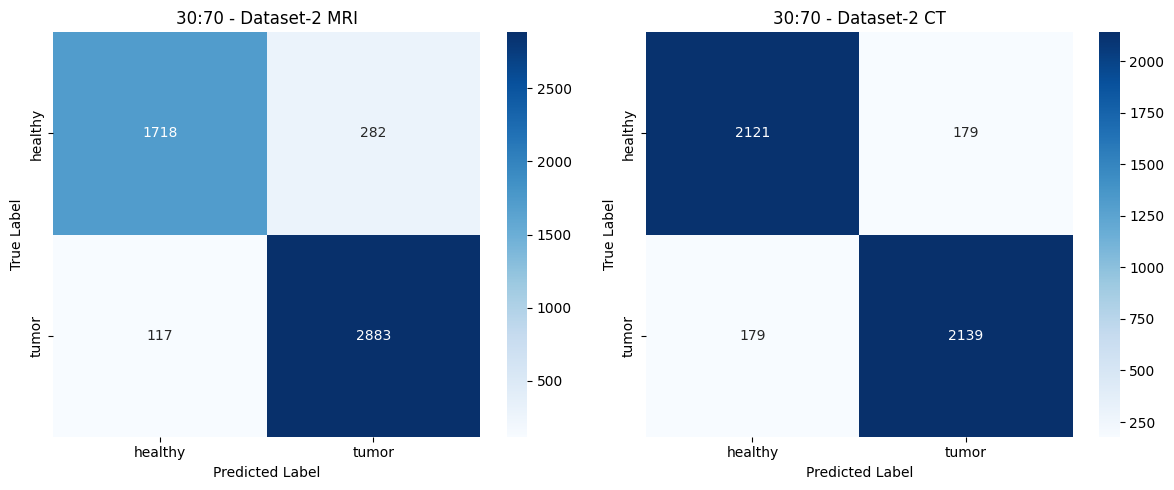

In [52]:
# ==========================================
# CELL 52 - 30:70 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI Confusion Matrix
sns.heatmap(
    mri_cm_30_70,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("30:70 - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# CT Confusion Matrix
sns.heatmap(
    ct_cm_30_70,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("30:70 - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [53]:
# ==========================================
# CELL 53 - CREATE 70:30 DATASET
# ==========================================

# MRI = 70% = 1400 images
# CT  = 30% = 600 images
# Each modality remains class-balanced

MRI_COUNT = 1400
CT_COUNT = 600

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2

# Sample MRI
mri_70_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_30_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)

# Combine MRI + CT
train_70_30_df = pd.concat(
    [mri_70_df, ct_30_df],
    ignore_index=True
)

# Shuffle
train_70_30_df = train_70_30_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Add modality column
train_70_30_df["modality"] = train_70_30_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)

print("70:30 DATASET")
print("=" * 50)
print("Total images:", len(train_70_30_df))

print("\nModality distribution:")
print(train_70_30_df["modality"].value_counts())

print("\nModality + class distribution:")
print(
    train_70_30_df.groupby(
        ["modality", "label"]
    ).size()
)

70:30 DATASET
Total images: 2000

Modality distribution:
modality
MRI    1400
CT      600
Name: count, dtype: int64

Modality + class distribution:
modality  label  
CT        healthy    300
          tumor      300
MRI       healthy    700
          tumor      700
dtype: int64


In [54]:
# ==========================================
# CELL 54 - 70:30 TRAIN/VALIDATION SPLIT
# ==========================================

# Create a combined stratification column
train_70_30_df["stratify_group"] = (
    train_70_30_df["modality"] + "_" +
    train_70_30_df["label"]
)

train_70_30, val_70_30 = train_test_split(
    train_70_30_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_70_30_df["stratify_group"]
)

# Reset indices
train_70_30 = train_70_30.reset_index(drop=True)
val_70_30 = val_70_30.reset_index(drop=True)

print("70:30 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print("Training samples  :", len(train_70_30))
print("Validation samples:", len(val_70_30))

print("\nTraining distribution:")
print(
    train_70_30.groupby(
        ["modality", "label"]
    ).size()
)

print("\nValidation distribution:")
print(
    val_70_30.groupby(
        ["modality", "label"]
    ).size()
)

70:30 TRAIN / VALIDATION SPLIT
Training samples  : 1600
Validation samples: 400

Training distribution:
modality  label  
CT        healthy    240
          tumor      240
MRI       healthy    560
          tumor      560
dtype: int64

Validation distribution:
modality  label  
CT        healthy     60
          tumor       60
MRI       healthy    140
          tumor      140
dtype: int64


In [55]:
# ==========================================
# CELL 55 - 70:30 DATA GENERATORS
# ==========================================

datagen_70_30 = ImageDataGenerator()

train_70_30_generator = datagen_70_30.flow_from_dataframe(
    dataframe=train_70_30,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_70_30_generator = datagen_70_30.flow_from_dataframe(
    dataframe=val_70_30,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n70:30 GENERATORS")
print("=" * 50)
print("Training samples  :", train_70_30_generator.samples)
print("Validation samples:", val_70_30_generator.samples)

print("\nClass mapping:")
print(train_70_30_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

70:30 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [56]:
# ==========================================
# CELL 56 - 70:30 MODEL
# ==========================================

base_model_70_30 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_70_30.trainable = False

model_70_30 = keras.Sequential([
    base_model_70_30,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_70_30.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("70:30 EfficientNetB0 model created successfully!")
model_70_30.summary()

70:30 EfficientNetB0 model created successfully!


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [57]:
# ==========================================
# CELL 57 - TRAIN 70:30 MODEL
# ==========================================

EPOCHS_70_30 = 10

early_stopping_70_30 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_70_30 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_70_30 = ModelCheckpoint(
    "/content/model_70_30.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_70_30 = model_70_30.fit(
    train_70_30_generator,
    validation_data=val_70_30_generator,
    epochs=EPOCHS_70_30,
    callbacks=[
        early_stopping_70_30,
        reduce_lr_70_30,
        checkpoint_70_30
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6510 - auc: 0.7029 - loss: 0.6319 - precision: 0.6899 - recall: 0.5655
Epoch 1: val_loss improved from None to 0.51491, saving model to /content/model_70_30.keras

Epoch 1: finished saving model to /content/model_70_30.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 370ms/step - accuracy: 0.6956 - auc: 0.7638 - loss: 0.5917 - precision: 0.7062 - recall: 0.6700 - val_accuracy: 0.7625 - val_auc: 0.8630 - val_loss: 0.5149 - val_precision: 0.7442 - val_recall: 0.8000 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.7822 - auc: 0.8713 - loss: 0.4943 - precision: 0.7960 - recall: 0.7588
Epoch 2: val_loss improved from 0.51491 to 0.42661, saving model to /content/model_70_30.keras

Epoch 2: finished saving model to /content/model_70_30.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step - accuracy: 0.8062 - auc: 0.8925 - loss: 0.4636 - precision: 0.8117 - recall: 0.7975 - val_accuracy: 0.8100 - val_

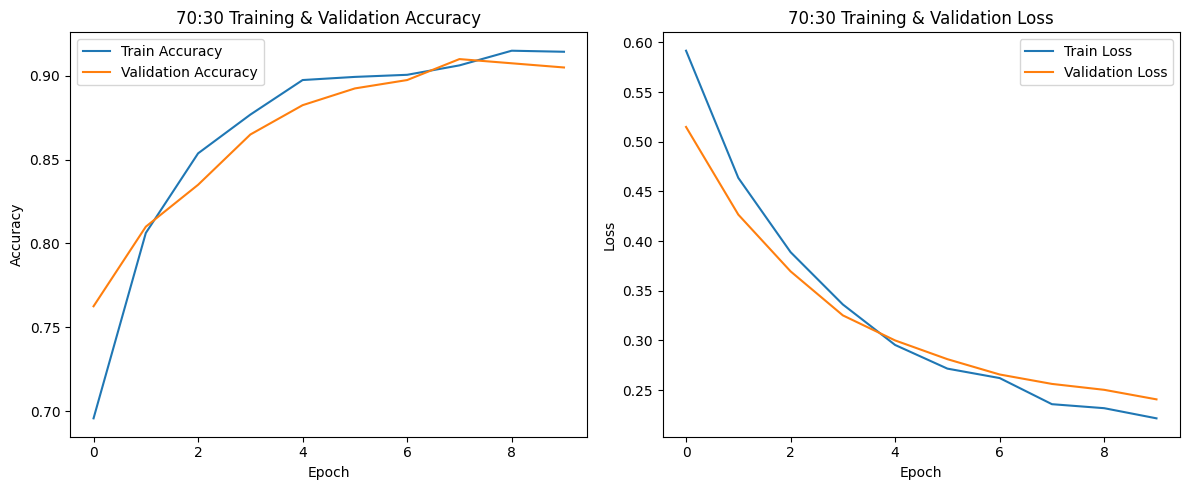

In [58]:
# ==========================================
# CELL 58 - 70:30 TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_70_30.history["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    history_70_30.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("70:30 Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_70_30.history["loss"],
    label="Train Loss"
)
plt.plot(
    history_70_30.history["val_loss"],
    label="Validation Loss"
)
plt.title("70:30 Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [59]:
# ==========================================
# CELL 59 - 70:30 DATASET-2 EVALUATION
# ==========================================

print("Evaluating 70:30 model on Dataset-2 MRI...")
mri_results_70_30 = model_70_30.evaluate(
    d2_mri_generator,
    verbose=1
)

print("\nEvaluating 70:30 model on Dataset-2 CT...")
ct_results_70_30 = model_70_30.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\n70:30 EVALUATION COMPLETED")

Evaluating 70:30 model on Dataset-2 MRI...
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 119ms/step - accuracy: 0.9450 - auc: 0.9863 - loss: 0.1616 - precision: 0.9477 - recall: 0.9613

Evaluating 70:30 model on Dataset-2 CT...
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 163ms/step - accuracy: 0.9004 - auc: 0.9602 - loss: 0.2585 - precision: 0.9100 - recall: 0.8896

70:30 EVALUATION COMPLETED


In [60]:
# ==========================================
# CELL 60 - 70:30 PREDICTIONS
# ==========================================

# Reset generators before prediction
d2_mri_generator.reset()
d2_ct_generator.reset()

# Predict probabilities
mri_prob_70_30 = model_70_30.predict(
    d2_mri_generator,
    verbose=1
).ravel()

ct_prob_70_30 = model_70_30.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to class predictions
mri_pred_70_30 = (mri_prob_70_30 >= 0.5).astype(int)
ct_pred_70_30 = (ct_prob_70_30 >= 0.5).astype(int)

# True labels
mri_true_70_30 = d2_mri_generator.classes
ct_true_70_30 = d2_ct_generator.classes

print("\n70:30 predictions generated successfully!")
print("MRI predictions:", len(mri_pred_70_30))
print("CT predictions :", len(ct_pred_70_30))

157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 133ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 160ms/step

70:30 predictions generated successfully!
MRI predictions: 5000
CT predictions : 4618


In [61]:
# ==========================================
# CELL 61 - 70:30 DETAILED METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_70_30 = accuracy_score(
    mri_true_70_30,
    mri_pred_70_30
)

mri_precision_70_30 = precision_score(
    mri_true_70_30,
    mri_pred_70_30
)

mri_recall_70_30 = recall_score(
    mri_true_70_30,
    mri_pred_70_30
)

mri_f1_70_30 = f1_score(
    mri_true_70_30,
    mri_pred_70_30
)

mri_auc_70_30 = roc_auc_score(
    mri_true_70_30,
    mri_prob_70_30
)

mri_cm_70_30 = confusion_matrix(
    mri_true_70_30,
    mri_pred_70_30
)


# ---------- CT ----------
ct_accuracy_70_30 = accuracy_score(
    ct_true_70_30,
    ct_pred_70_30
)

ct_precision_70_30 = precision_score(
    ct_true_70_30,
    ct_pred_70_30
)

ct_recall_70_30 = recall_score(
    ct_true_70_30,
    ct_pred_70_30
)

ct_f1_70_30 = f1_score(
    ct_true_70_30,
    ct_pred_70_30
)

ct_auc_70_30 = roc_auc_score(
    ct_true_70_30,
    ct_prob_70_30
)

ct_cm_70_30 = confusion_matrix(
    ct_true_70_30,
    ct_pred_70_30
)


# ---------- Print Results ----------
print("70:30 RESULTS ON DATASET-2")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy : {mri_accuracy_70_30:.4f}")
print(f"Precision: {mri_precision_70_30:.4f}")
print(f"Recall   : {mri_recall_70_30:.4f}")
print(f"F1 Score : {mri_f1_70_30:.4f}")
print(f"AUC      : {mri_auc_70_30:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy : {ct_accuracy_70_30:.4f}")
print(f"Precision: {ct_precision_70_30:.4f}")
print(f"Recall   : {ct_recall_70_30:.4f}")
print(f"F1 Score : {ct_f1_70_30:.4f}")
print(f"AUC      : {ct_auc_70_30:.4f}")

70:30 RESULTS ON DATASET-2

MRI RESULTS
------------------------------
Accuracy : 0.9450
Precision: 0.9477
Recall   : 0.9613
F1 Score : 0.9545
AUC      : 0.9863

CT RESULTS
------------------------------
Accuracy : 0.9004
Precision: 0.9100
Recall   : 0.8896
F1 Score : 0.8997
AUC      : 0.9602


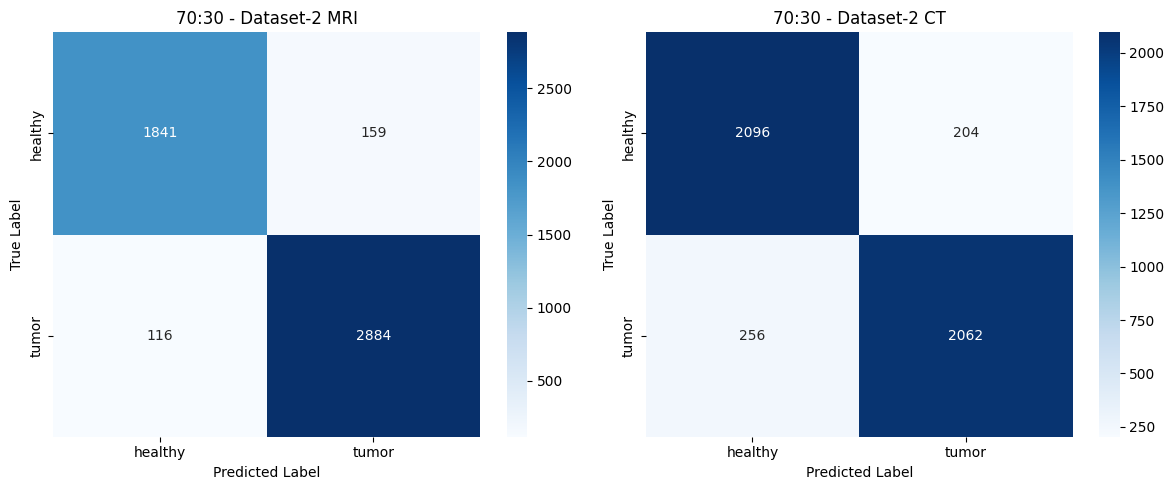

In [62]:
# ==========================================
# CELL 62 - 70:30 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI Confusion Matrix
sns.heatmap(
    mri_cm_70_30,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("70:30 - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# CT Confusion Matrix
sns.heatmap(
    ct_cm_70_30,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("70:30 - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [63]:
# ==========================================
# CELL 63 - CREATE 20:80 DATASET
# ==========================================

# MRI = 20% = 400 images
# CT  = 80% = 1600 images
# Each modality remains class-balanced

MRI_COUNT = 400
CT_COUNT = 1600

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2

# Sample MRI
mri_20_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_80_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)

# Combine MRI + CT
train_20_80_df = pd.concat(
    [mri_20_df, ct_80_df],
    ignore_index=True
)

# Shuffle
train_20_80_df = train_20_80_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Add modality column
train_20_80_df["modality"] = train_20_80_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)

print("20:80 DATASET")
print("=" * 50)
print("Total images:", len(train_20_80_df))

print("\nModality distribution:")
print(train_20_80_df["modality"].value_counts())

print("\nModality + class distribution:")
print(
    train_20_80_df.groupby(
        ["modality", "label"]
    ).size()
)

20:80 DATASET
Total images: 2000

Modality distribution:
modality
CT     1600
MRI     400
Name: count, dtype: int64

Modality + class distribution:
modality  label  
CT        healthy    800
          tumor      800
MRI       healthy    200
          tumor      200
dtype: int64


In [64]:
# ==========================================
# CELL 64 - 20:80 TRAIN/VALIDATION SPLIT
# ==========================================

# Create a combined stratification column
train_20_80_df["stratify_group"] = (
    train_20_80_df["modality"] + "_" +
    train_20_80_df["label"]
)

train_20_80, val_20_80 = train_test_split(
    train_20_80_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_20_80_df["stratify_group"]
)

# Reset indices
train_20_80 = train_20_80.reset_index(drop=True)
val_20_80 = val_20_80.reset_index(drop=True)

print("20:80 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print("Training samples  :", len(train_20_80))
print("Validation samples:", len(val_20_80))

print("\nTraining distribution:")
print(
    train_20_80.groupby(
        ["modality", "label"]
    ).size()
)

print("\nValidation distribution:")
print(
    val_20_80.groupby(
        ["modality", "label"]
    ).size()
)

20:80 TRAIN / VALIDATION SPLIT
Training samples  : 1600
Validation samples: 400

Training distribution:
modality  label  
CT        healthy    640
          tumor      640
MRI       healthy    160
          tumor      160
dtype: int64

Validation distribution:
modality  label  
CT        healthy    160
          tumor      160
MRI       healthy     40
          tumor       40
dtype: int64


In [65]:
# ==========================================
# CELL 65 - 20:80 DATA GENERATORS
# ==========================================

datagen_20_80 = ImageDataGenerator()

train_20_80_generator = datagen_20_80.flow_from_dataframe(
    dataframe=train_20_80,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_20_80_generator = datagen_20_80.flow_from_dataframe(
    dataframe=val_20_80,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n20:80 GENERATORS")
print("=" * 50)
print("Training samples  :", train_20_80_generator.samples)
print("Validation samples:", val_20_80_generator.samples)

print("\nClass mapping:")
print(train_20_80_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

20:80 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [66]:
# ==========================================
# CELL 66 - 20:80 MODEL
# ==========================================

base_model_20_80 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_20_80.trainable = False

model_20_80 = keras.Sequential([
    base_model_20_80,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_20_80.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("20:80 EfficientNetB0 model created successfully!")
model_20_80.summary()

20:80 EfficientNetB0 model created successfully!


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [67]:
# ==========================================
# CELL 67 - TRAIN 20:80 MODEL
# ==========================================

EPOCHS_20_80 = 10

early_stopping_20_80 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_20_80 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_20_80 = ModelCheckpoint(
    "/content/model_20_80.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_20_80 = model_20_80.fit(
    train_20_80_generator,
    validation_data=val_20_80_generator,
    epochs=EPOCHS_20_80,
    callbacks=[
        early_stopping_20_80,
        reduce_lr_20_80,
        checkpoint_20_80
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.6072 - auc: 0.6558 - loss: 0.6544 - precision: 0.6336 - recall: 0.5708
Epoch 1: val_loss improved from None to 0.46533, saving model to /content/model_20_80.keras

Epoch 1: finished saving model to /content/model_20_80.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 377ms/step - accuracy: 0.6562 - auc: 0.7238 - loss: 0.6109 - precision: 0.6653 - recall: 0.6288 - val_accuracy: 0.8550 - val_auc: 0.9235 - val_loss: 0.4653 - val_precision: 0.8737 - val_recall: 0.8300 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.7808 - auc: 0.8618 - loss: 0.4966 - precision: 0.7866 - recall: 0.7713
Epoch 2: val_loss improved from 0.46533 to 0.36703, saving model to /content/model_20_80.keras

Epoch 2: finished saving model to /content/model_20_80.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 156ms/step - accuracy: 0.8019 - auc: 0.8788 - loss: 0.4734 - precision: 0.8092 - recall: 0.7900 - val_accuracy: 0.8875 - val_

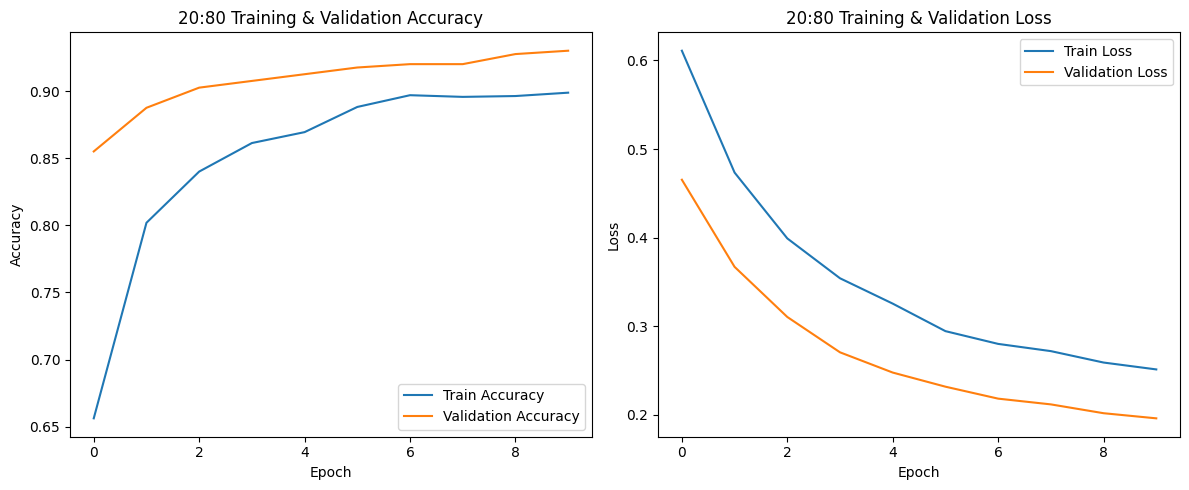

In [68]:
# ==========================================
# CELL 68 - 20:80 TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_20_80.history["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    history_20_80.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("20:80 Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_20_80.history["loss"],
    label="Train Loss"
)
plt.plot(
    history_20_80.history["val_loss"],
    label="Validation Loss"
)
plt.title("20:80 Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [69]:
# ==========================================
# CELL 69 - 20:80 DATASET-2 EVALUATION
# ==========================================

print("Evaluating 20:80 model on Dataset-2 MRI...")
mri_results_20_80 = model_20_80.evaluate(
    d2_mri_generator,
    verbose=1
)

print("\nEvaluating 20:80 model on Dataset-2 CT...")
ct_results_20_80 = model_20_80.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\n20:80 EVALUATION COMPLETED")

Evaluating 20:80 model on Dataset-2 MRI...
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 128ms/step - accuracy: 0.9172 - auc: 0.9702 - loss: 0.2436 - precision: 0.9187 - recall: 0.9457

Evaluating 20:80 model on Dataset-2 CT...
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step - accuracy: 0.9359 - auc: 0.9792 - loss: 0.1878 - precision: 0.9546 - recall: 0.9159

20:80 EVALUATION COMPLETED


In [70]:
# ==========================================
# CELL 70 - 20:80 PREDICTIONS
# ==========================================

# Reset generators before prediction
d2_mri_generator.reset()
d2_ct_generator.reset()

# Predict probabilities
mri_prob_20_80 = model_20_80.predict(
    d2_mri_generator,
    verbose=1
).ravel()

ct_prob_20_80 = model_20_80.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to class predictions
mri_pred_20_80 = (mri_prob_20_80 >= 0.5).astype(int)
ct_pred_20_80 = (ct_prob_20_80 >= 0.5).astype(int)

# True labels
mri_true_20_80 = d2_mri_generator.classes
ct_true_20_80 = d2_ct_generator.classes

print("\n20:80 predictions generated successfully!")
print("MRI predictions:", len(mri_pred_20_80))
print("CT predictions :", len(ct_pred_20_80))

157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 134ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 20s 141ms/step

20:80 predictions generated successfully!
MRI predictions: 5000
CT predictions : 4618


In [71]:
# ==========================================
# CELL 71 - 20:80 DETAILED METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_20_80 = accuracy_score(
    mri_true_20_80,
    mri_pred_20_80
)

mri_precision_20_80 = precision_score(
    mri_true_20_80,
    mri_pred_20_80
)

mri_recall_20_80 = recall_score(
    mri_true_20_80,
    mri_pred_20_80
)

mri_f1_20_80 = f1_score(
    mri_true_20_80,
    mri_pred_20_80
)

mri_auc_20_80 = roc_auc_score(
    mri_true_20_80,
    mri_prob_20_80
)

mri_cm_20_80 = confusion_matrix(
    mri_true_20_80,
    mri_pred_20_80
)


# ---------- CT ----------
ct_accuracy_20_80 = accuracy_score(
    ct_true_20_80,
    ct_pred_20_80
)

ct_precision_20_80 = precision_score(
    ct_true_20_80,
    ct_pred_20_80
)

ct_recall_20_80 = recall_score(
    ct_true_20_80,
    ct_pred_20_80
)

ct_f1_20_80 = f1_score(
    ct_true_20_80,
    ct_pred_20_80
)

ct_auc_20_80 = roc_auc_score(
    ct_true_20_80,
    ct_prob_20_80
)

ct_cm_20_80 = confusion_matrix(
    ct_true_20_80,
    ct_pred_20_80
)


# ---------- Print Results ----------
print("20:80 RESULTS ON DATASET-2")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy : {mri_accuracy_20_80:.4f}")
print(f"Precision: {mri_precision_20_80:.4f}")
print(f"Recall   : {mri_recall_20_80:.4f}")
print(f"F1 Score : {mri_f1_20_80:.4f}")
print(f"AUC      : {mri_auc_20_80:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy : {ct_accuracy_20_80:.4f}")
print(f"Precision: {ct_precision_20_80:.4f}")
print(f"Recall   : {ct_recall_20_80:.4f}")
print(f"F1 Score : {ct_f1_20_80:.4f}")
print(f"AUC      : {ct_auc_20_80:.4f}")

20:80 RESULTS ON DATASET-2

MRI RESULTS
------------------------------
Accuracy : 0.9172
Precision: 0.9187
Recall   : 0.9457
F1 Score : 0.9320
AUC      : 0.9702

CT RESULTS
------------------------------
Accuracy : 0.9359
Precision: 0.9546
Recall   : 0.9159
F1 Score : 0.9348
AUC      : 0.9792


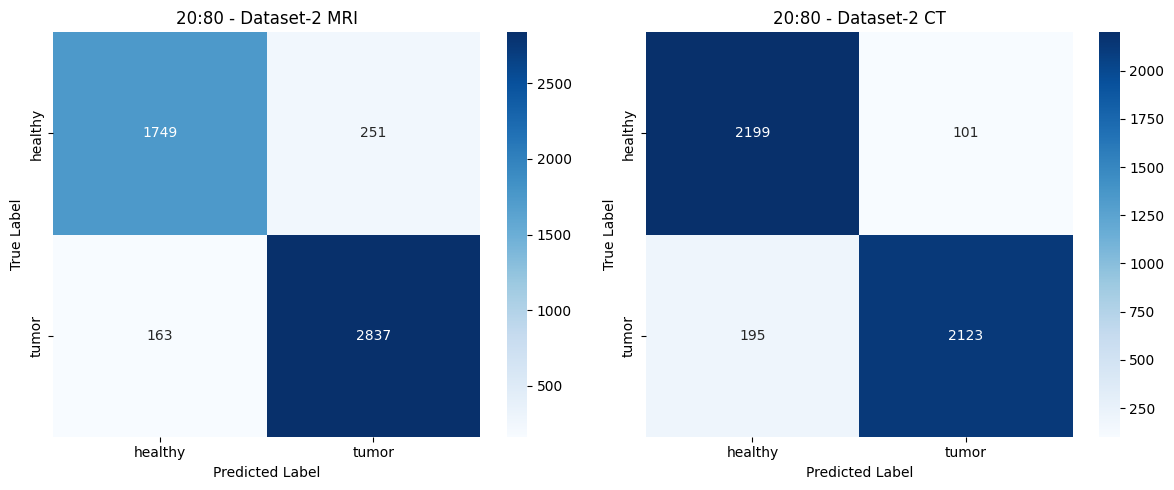

In [72]:
# ==========================================
# CELL 72 - 20:80 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI Confusion Matrix
sns.heatmap(
    mri_cm_20_80,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("20:80 - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# CT Confusion Matrix
sns.heatmap(
    ct_cm_20_80,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("20:80 - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [73]:
# ==========================================
# CELL 73 - CREATE 80:20 DATASET
# ==========================================

# MRI = 80% = 1600 images
# CT  = 20% = 400 images
# Each modality remains class-balanced

MRI_COUNT = 1600
CT_COUNT = 400

MRI_HEALTHY = MRI_COUNT // 2
MRI_TUMOR = MRI_COUNT // 2

CT_HEALTHY = CT_COUNT // 2
CT_TUMOR = CT_COUNT // 2

# Sample MRI
mri_80_df = sample_balanced_modality(
    d1_mri_df,
    MRI_HEALTHY,
    MRI_TUMOR
)

# Sample CT
ct_20_df = sample_balanced_modality(
    d1_ct_df,
    CT_HEALTHY,
    CT_TUMOR
)

# Combine MRI + CT
train_80_20_df = pd.concat(
    [mri_80_df, ct_20_df],
    ignore_index=True
)

# Shuffle
train_80_20_df = train_80_20_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Add modality column
train_80_20_df["modality"] = train_80_20_df["filepath"].apply(
    lambda x: "MRI" if f"{os.sep}mri{os.sep}" in x else "CT"
)

print("80:20 DATASET")
print("=" * 50)
print("Total images:", len(train_80_20_df))

print("\nModality distribution:")
print(train_80_20_df["modality"].value_counts())

print("\nModality + class distribution:")
print(
    train_80_20_df.groupby(
        ["modality", "label"]
    ).size()
)

80:20 DATASET
Total images: 2000

Modality distribution:
modality
MRI    1600
CT      400
Name: count, dtype: int64

Modality + class distribution:
modality  label  
CT        healthy    200
          tumor      200
MRI       healthy    800
          tumor      800
dtype: int64


In [74]:
# ==========================================
# CELL 74 - 80:20 TRAIN/VALIDATION SPLIT
# ==========================================

# Create a combined stratification column
train_80_20_df["stratify_group"] = (
    train_80_20_df["modality"] + "_" +
    train_80_20_df["label"]
)

train_80_20, val_80_20 = train_test_split(
    train_80_20_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_80_20_df["stratify_group"]
)

# Reset indices
train_80_20 = train_80_20.reset_index(drop=True)
val_80_20 = val_80_20.reset_index(drop=True)

print("80:20 TRAIN / VALIDATION SPLIT")
print("=" * 50)

print("Training samples  :", len(train_80_20))
print("Validation samples:", len(val_80_20))

print("\nTraining distribution:")
print(
    train_80_20.groupby(
        ["modality", "label"]
    ).size()
)

print("\nValidation distribution:")
print(
    val_80_20.groupby(
        ["modality", "label"]
    ).size()
)

80:20 TRAIN / VALIDATION SPLIT
Training samples  : 1600
Validation samples: 400

Training distribution:
modality  label  
CT        healthy    160
          tumor      160
MRI       healthy    640
          tumor      640
dtype: int64

Validation distribution:
modality  label  
CT        healthy     40
          tumor       40
MRI       healthy    160
          tumor      160
dtype: int64


In [75]:
# ==========================================
# CELL 75 - 80:20 DATA GENERATORS
# ==========================================

datagen_80_20 = ImageDataGenerator()

train_80_20_generator = datagen_80_20.flow_from_dataframe(
    dataframe=train_80_20,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_80_20_generator = datagen_80_20.flow_from_dataframe(
    dataframe=val_80_20,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    classes=CLASS_NAMES,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\n80:20 GENERATORS")
print("=" * 50)
print("Training samples  :", train_80_20_generator.samples)
print("Validation samples:", val_80_20_generator.samples)

print("\nClass mapping:")
print(train_80_20_generator.class_indices)

Found 1600 validated image filenames belonging to 2 classes.
Found 400 validated image filenames belonging to 2 classes.

80:20 GENERATORS
Training samples  : 1600
Validation samples: 400

Class mapping:
{'healthy': 0, 'tumor': 1}


In [76]:
# ==========================================
# CELL 76 - 80:20 MODEL
# ==========================================

base_model_80_20 = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_80_20.trainable = False

model_80_20 = keras.Sequential([
    base_model_80_20,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model_80_20.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

print("80:20 EfficientNetB0 model created successfully!")
model_80_20.summary()

80:20 EfficientNetB0 model created successfully!


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [77]:
# ==========================================
# CELL 77 - TRAIN 80:20 MODEL
# ==========================================

EPOCHS_80_20 = 10

early_stopping_80_20 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_80_20 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_80_20 = ModelCheckpoint(
    "/content/model_80_20.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_80_20 = model_80_20.fit(
    train_80_20_generator,
    validation_data=val_80_20_generator,
    epochs=EPOCHS_80_20,
    callbacks=[
        early_stopping_80_20,
        reduce_lr_80_20,
        checkpoint_80_20
    ]
)

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5796 - auc: 0.6224 - loss: 0.6679 - precision: 0.5771 - recall: 0.6065
Epoch 1: val_loss improved from None to 0.49713, saving model to /content/model_80_20.keras

Epoch 1: finished saving model to /content/model_80_20.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 366ms/step - accuracy: 0.6656 - auc: 0.7378 - loss: 0.6052 - precision: 0.6614 - recall: 0.6787 - val_accuracy: 0.7750 - val_auc: 0.8781 - val_loss: 0.4971 - val_precision: 0.7926 - val_recall: 0.7450 - learning_rate: 1.0000e-04
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.7918 - auc: 0.8803 - loss: 0.4761 - precision: 0.7770 - recall: 0.8134
Epoch 2: val_loss improved from 0.49713 to 0.40986, saving model to /content/model_80_20.keras

Epoch 2: finished saving model to /content/model_80_20.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 149ms/step - accuracy: 0.8087 - auc: 0.8929 - loss: 0.4588 - precision: 0.8057 - recall: 0.8138 - val_accuracy: 0.8250 - val_

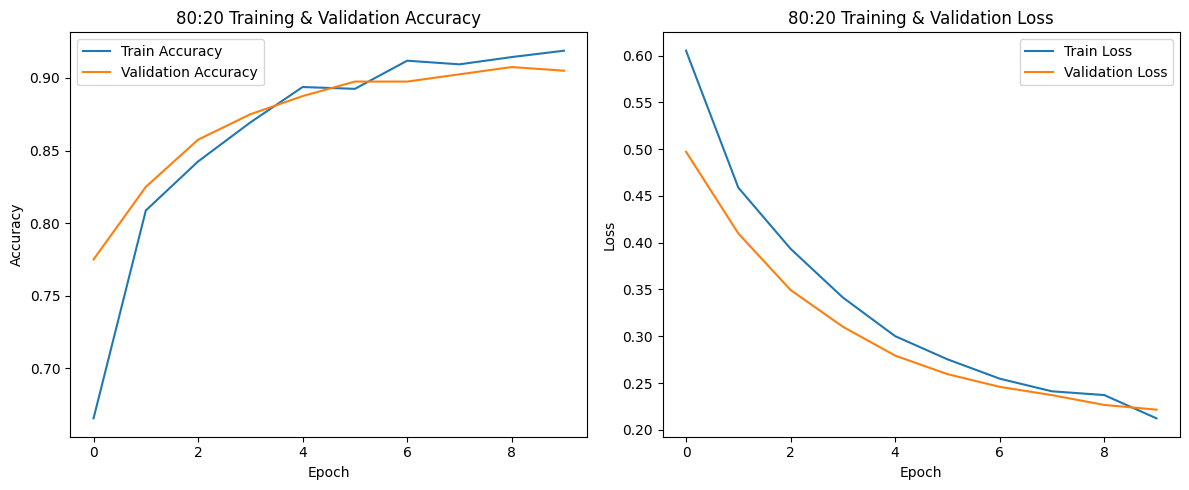

In [78]:
# ==========================================
# CELL 78 - 80:20 TRAINING CURVES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_80_20.history["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    history_80_20.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("80:20 Training & Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_80_20.history["loss"],
    label="Train Loss"
)
plt.plot(
    history_80_20.history["val_loss"],
    label="Validation Loss"
)
plt.title("80:20 Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [79]:
# ==========================================
# CELL 79 - 80:20 DATASET-2 EVALUATION
# ==========================================

print("Evaluating 80:20 model on Dataset-2 MRI...")
mri_results_80_20 = model_80_20.evaluate(
    d2_mri_generator,
    verbose=1
)

print("\nEvaluating 80:20 model on Dataset-2 CT...")
ct_results_80_20 = model_80_20.evaluate(
    d2_ct_generator,
    verbose=1
)

print("\n80:20 EVALUATION COMPLETED")

Evaluating 80:20 model on Dataset-2 MRI...
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 125ms/step - accuracy: 0.9442 - auc: 0.9880 - loss: 0.1528 - precision: 0.9576 - recall: 0.9490

Evaluating 80:20 model on Dataset-2 CT...
145/145 ━━━━━━━━━━━━━━━━━━━━ 24s 168ms/step - accuracy: 0.8900 - auc: 0.9486 - loss: 0.2925 - precision: 0.9077 - recall: 0.8693

80:20 EVALUATION COMPLETED


In [80]:
# ==========================================
# CELL 80 - 80:20 PREDICTIONS
# ==========================================

# Reset generators before prediction
d2_mri_generator.reset()
d2_ct_generator.reset()

# Predict probabilities
mri_prob_80_20 = model_80_20.predict(
    d2_mri_generator,
    verbose=1
).ravel()

ct_prob_80_20 = model_80_20.predict(
    d2_ct_generator,
    verbose=1
).ravel()

# Convert probabilities to class predictions
mri_pred_80_20 = (mri_prob_80_20 >= 0.5).astype(int)
ct_pred_80_20 = (ct_prob_80_20 >= 0.5).astype(int)

# True labels
mri_true_80_20 = d2_mri_generator.classes
ct_true_80_20 = d2_ct_generator.classes

print("\n80:20 predictions generated successfully!")
print("MRI predictions:", len(mri_pred_80_20))
print("CT predictions :", len(ct_pred_80_20))

157/157 ━━━━━━━━━━━━━━━━━━━━ 27s 133ms/step
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 162ms/step

80:20 predictions generated successfully!
MRI predictions: 5000
CT predictions : 4618


In [81]:
# ==========================================
# CELL 81 - 80:20 DETAILED METRICS
# ==========================================

# ---------- MRI ----------
mri_accuracy_80_20 = accuracy_score(
    mri_true_80_20,
    mri_pred_80_20
)

mri_precision_80_20 = precision_score(
    mri_true_80_20,
    mri_pred_80_20
)

mri_recall_80_20 = recall_score(
    mri_true_80_20,
    mri_pred_80_20
)

mri_f1_80_20 = f1_score(
    mri_true_80_20,
    mri_pred_80_20
)

mri_auc_80_20 = roc_auc_score(
    mri_true_80_20,
    mri_prob_80_20
)

mri_cm_80_20 = confusion_matrix(
    mri_true_80_20,
    mri_pred_80_20
)


# ---------- CT ----------
ct_accuracy_80_20 = accuracy_score(
    ct_true_80_20,
    ct_pred_80_20
)

ct_precision_80_20 = precision_score(
    ct_true_80_20,
    ct_pred_80_20
)

ct_recall_80_20 = recall_score(
    ct_true_80_20,
    ct_pred_80_20
)

ct_f1_80_20 = f1_score(
    ct_true_80_20,
    ct_pred_80_20
)

ct_auc_80_20 = roc_auc_score(
    ct_true_80_20,
    ct_prob_80_20
)

ct_cm_80_20 = confusion_matrix(
    ct_true_80_20,
    ct_pred_80_20
)


# ---------- Print Results ----------
print("80:20 RESULTS ON DATASET-2")
print("=" * 60)

print("\nMRI RESULTS")
print("-" * 30)
print(f"Accuracy : {mri_accuracy_80_20:.4f}")
print(f"Precision: {mri_precision_80_20:.4f}")
print(f"Recall   : {mri_recall_80_20:.4f}")
print(f"F1 Score : {mri_f1_80_20:.4f}")
print(f"AUC      : {mri_auc_80_20:.4f}")

print("\nCT RESULTS")
print("-" * 30)
print(f"Accuracy : {ct_accuracy_80_20:.4f}")
print(f"Precision: {ct_precision_80_20:.4f}")
print(f"Recall   : {ct_recall_80_20:.4f}")
print(f"F1 Score : {ct_f1_80_20:.4f}")
print(f"AUC      : {ct_auc_80_20:.4f}")

80:20 RESULTS ON DATASET-2

MRI RESULTS
------------------------------
Accuracy : 0.9442
Precision: 0.9576
Recall   : 0.9490
F1 Score : 0.9533
AUC      : 0.9879

CT RESULTS
------------------------------
Accuracy : 0.8900
Precision: 0.9077
Recall   : 0.8693
F1 Score : 0.8881
AUC      : 0.9486


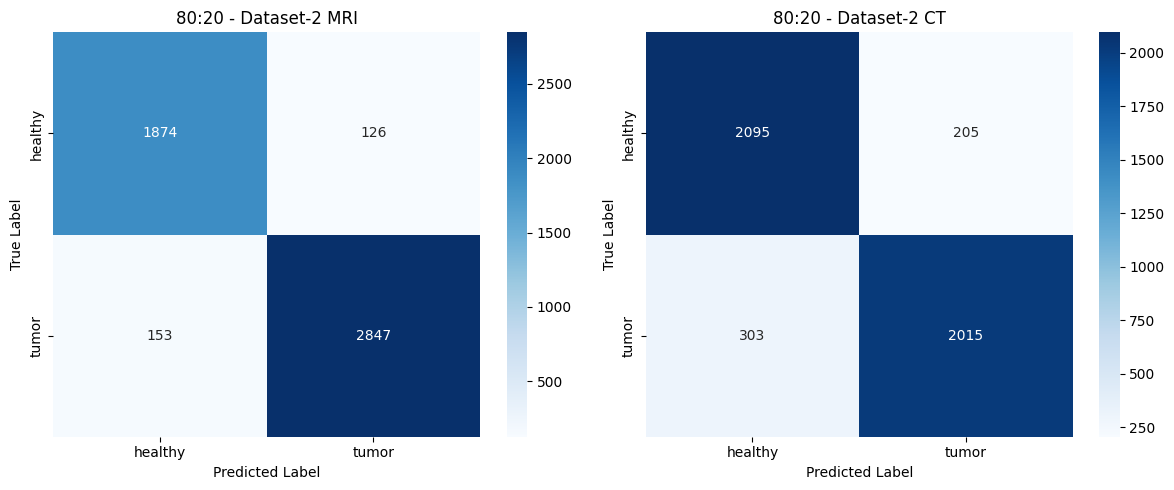

In [82]:
# ==========================================
# CELL 82 - 80:20 CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MRI Confusion Matrix
sns.heatmap(
    mri_cm_80_20,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[0]
)

axes[0].set_title("80:20 - Dataset-2 MRI")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# CT Confusion Matrix
sns.heatmap(
    ct_cm_80_20,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axes[1]
)

axes[1].set_title("80:20 - Dataset-2 CT")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [83]:
# ==========================================
# CELL 83 - MASTER RESULTS TABLE
# ==========================================

results = [
    {
        "Ratio": "50:50",
        "MRI %": 50,
        "CT %": 50,
        "MRI Accuracy": mri_accuracy_50,
        "MRI Precision": mri_precision_50,
        "MRI Recall": mri_recall_50,
        "MRI F1": mri_f1_50,
        "MRI AUC": mri_auc_50,
        "CT Accuracy": ct_accuracy_50,
        "CT Precision": ct_precision_50,
        "CT Recall": ct_recall_50,
        "CT F1": ct_f1_50,
        "CT AUC": ct_auc_50
    },
    {
        "Ratio": "40:60",
        "MRI %": 40,
        "CT %": 60,
        "MRI Accuracy": mri_accuracy_40_60,
        "MRI Precision": mri_precision_40_60,
        "MRI Recall": mri_recall_40_60,
        "MRI F1": mri_f1_40_60,
        "MRI AUC": mri_auc_40_60,
        "CT Accuracy": ct_accuracy_40_60,
        "CT Precision": ct_precision_40_60,
        "CT Recall": ct_recall_40_60,
        "CT F1": ct_f1_40_60,
        "CT AUC": ct_auc_40_60
    },
    {
        "Ratio": "60:40",
        "MRI %": 60,
        "CT %": 40,
        "MRI Accuracy": mri_accuracy_60_40,
        "MRI Precision": mri_precision_60_40,
        "MRI Recall": mri_recall_60_40,
        "MRI F1": mri_f1_60_40,
        "MRI AUC": mri_auc_60_40,
        "CT Accuracy": ct_accuracy_60_40,
        "CT Precision": ct_precision_60_40,
        "CT Recall": ct_recall_60_40,
        "CT F1": ct_f1_60_40,
        "CT AUC": ct_auc_60_40
    },
    {
        "Ratio": "30:70",
        "MRI %": 30,
        "CT %": 70,
        "MRI Accuracy": mri_accuracy_30_70,
        "MRI Precision": mri_precision_30_70,
        "MRI Recall": mri_recall_30_70,
        "MRI F1": mri_f1_30_70,
        "MRI AUC": mri_auc_30_70,
        "CT Accuracy": ct_accuracy_30_70,
        "CT Precision": ct_precision_30_70,
        "CT Recall": ct_recall_30_70,
        "CT F1": ct_f1_30_70,
        "CT AUC": ct_auc_30_70
    },
    {
        "Ratio": "70:30",
        "MRI %": 70,
        "CT %": 30,
        "MRI Accuracy": mri_accuracy_70_30,
        "MRI Precision": mri_precision_70_30,
        "MRI Recall": mri_recall_70_30,
        "MRI F1": mri_f1_70_30,
        "MRI AUC": mri_auc_70_30,
        "CT Accuracy": ct_accuracy_70_30,
        "CT Precision": ct_precision_70_30,
        "CT Recall": ct_recall_70_30,
        "CT F1": ct_f1_70_30,
        "CT AUC": ct_auc_70_30
    },
    {
        "Ratio": "20:80",
        "MRI %": 20,
        "CT %": 80,
        "MRI Accuracy": mri_accuracy_20_80,
        "MRI Precision": mri_precision_20_80,
        "MRI Recall": mri_recall_20_80,
        "MRI F1": mri_f1_20_80,
        "MRI AUC": mri_auc_20_80,
        "CT Accuracy": ct_accuracy_20_80,
        "CT Precision": ct_precision_20_80,
        "CT Recall": ct_recall_20_80,
        "CT F1": ct_f1_20_80,
        "CT AUC": ct_auc_20_80
    },
    {
        "Ratio": "80:20",
        "MRI %": 80,
        "CT %": 20,
        "MRI Accuracy": mri_accuracy_80_20,
        "MRI Precision": mri_precision_80_20,
        "MRI Recall": mri_recall_80_20,
        "MRI F1": mri_f1_80_20,
        "MRI AUC": mri_auc_80_20,
        "CT Accuracy": ct_accuracy_80_20,
        "CT Precision": ct_precision_80_20,
        "CT Recall": ct_recall_80_20,
        "CT F1": ct_f1_80_20,
        "CT AUC": ct_auc_80_20
    }
]

results_df = pd.DataFrame(results)

# Arrange ratios in experimental order
ratio_order = [
    "50:50",
    "40:60",
    "60:40",
    "30:70",
    "70:30",
    "20:80",
    "80:20"
]

results_df["Ratio"] = pd.Categorical(
    results_df["Ratio"],
    categories=ratio_order,
    ordered=True
)

results_df = results_df.sort_values("Ratio").reset_index(drop=True)

print("MASTER RESULTS TABLE")
print("=" * 80)

display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.columns
        if col not in ["Ratio", "MRI %", "CT %"]
    })
)

MASTER RESULTS TABLE


,Ratio,MRI %,CT %,MRI Accuracy,MRI Precision,MRI Recall,MRI F1,MRI AUC,CT Accuracy,CT Precision,CT Recall,CT F1,CT AUC
0,50:50,50,50,0.9354,0.9350,0.9590,0.9468,0.9828,0.9201,0.9231,0.9172,0.9201,0.9710
1,40:60,40,60,0.9228,0.9203,0.9540,0.9368,0.9779,0.9275,0.9448,0.9085,0.9263,0.9747
2,60:40,60,40,0.9398,0.9479,0.9520,0.9499,0.9849,0.9073,0.9145,0.8995,0.9069,0.9656
3,30:70,30,70,0.9202,0.9109,0.9610,0.9353,0.9777,0.9225,0.9228,0.9228,0.9228,0.9756
4,70:30,70,30,0.9450,0.9477,0.9613,0.9545,0.9863,0.9004,0.9100,0.8896,0.8997,0.9602
5,20:80,20,80,0.9172,0.9187,0.9457,0.9320,0.9702,0.9359,0.9546,0.9159,0.9348,0.9792
6,80:20,80,20,0.9442,0.9576,0.9490,0.9533,0.9879,0.8900,0.9077,0.8693,0.8881,0.9486


In [84]:
# ==========================================
# CELL 84 - MRI vs CT PERFORMANCE GAP
# ==========================================

gap_df = results_df[
    [
        "Ratio",
        "MRI %",
        "CT %",
        "MRI Accuracy",
        "CT Accuracy",
        "MRI F1",
        "CT F1",
        "MRI AUC",
        "CT AUC"
    ]
].copy()

# Calculate MRI - CT gaps
gap_df["Accuracy Gap (MRI-CT)"] = (
    gap_df["MRI Accuracy"] - gap_df["CT Accuracy"]
)

gap_df["F1 Gap (MRI-CT)"] = (
    gap_df["MRI F1"] - gap_df["CT F1"]
)

gap_df["AUC Gap (MRI-CT)"] = (
    gap_df["MRI AUC"] - gap_df["CT AUC"]
)

print("MRI vs CT PERFORMANCE GAP")
print("=" * 80)

display(
    gap_df.style.format({
        "MRI Accuracy": "{:.4f}",
        "CT Accuracy": "{:.4f}",
        "MRI F1": "{:.4f}",
        "CT F1": "{:.4f}",
        "MRI AUC": "{:.4f}",
        "CT AUC": "{:.4f}",
        "Accuracy Gap (MRI-CT)": "{:+.4f}",
        "F1 Gap (MRI-CT)": "{:+.4f}",
        "AUC Gap (MRI-CT)": "{:+.4f}"
    })
)

MRI vs CT PERFORMANCE GAP


,Ratio,MRI %,CT %,MRI Accuracy,CT Accuracy,MRI F1,CT F1,MRI AUC,CT AUC,Accuracy Gap (MRI-CT),F1 Gap (MRI-CT),AUC Gap (MRI-CT)
0,50:50,50,50,0.9354,0.9201,0.9468,0.9201,0.9828,0.9710,+0.0153,+0.0267,+0.0118
1,40:60,40,60,0.9228,0.9275,0.9368,0.9263,0.9779,0.9747,-0.0047,+0.0105,+0.0031
2,60:40,60,40,0.9398,0.9073,0.9499,0.9069,0.9849,0.9656,+0.0325,+0.0430,+0.0193
3,30:70,30,70,0.9202,0.9225,0.9353,0.9228,0.9777,0.9756,-0.0023,+0.0125,+0.0021
4,70:30,70,30,0.9450,0.9004,0.9545,0.8997,0.9863,0.9602,+0.0446,+0.0548,+0.0261
5,20:80,20,80,0.9172,0.9359,0.9320,0.9348,0.9702,0.9792,-0.0187,-0.0028,-0.0089
6,80:20,80,20,0.9442,0.8900,0.9533,0.8881,0.9879,0.9486,+0.0542,+0.0652,+0.0393
